# The Challenge of Manufacturing

In [66]:
# Import libraries
from matplotlib import pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.gridspec as gridspec
import numpy as np
import seaborn as sns
import pandas as pd

from process_improvement.charts.xmr_charts import xmr_chart
from process_improvement.charts.utils import XmRChartConfig

from process_improvement.charts.limit_charts import limit_chart
from process_improvement.charts.utils import LimitChartConfig

from process_improvement.charts.combo_chart import combo_chart
from process_improvement.charts.utils import ComboChartConfig

from process_improvement.charts.xmr_charts import xmr_comparison
from process_improvement.charts.utils import XmRCompConfig

# For Figures 10.6 and 10.7
from scipy.stats import gaussian_kde
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from mpl_toolkits.mplot3d import Axes3D

%matplotlib inline

## Get the data

In [67]:
# Dataset url
dataset_url = r'https://raw.githubusercontent.com/jimlehner/presentations/refs/heads/main/data/shewharts-resistance-measurements.csv'

# Get data
def get_data() -> pd.DataFrame:
    return pd.read_csv(dataset_url)

# Get data
resistance_df = get_data()

# Make 'Year' column dtype string
resistance_df['Value'] = resistance_df['Value'].astype('string')

# Drop 'Units' column
resistance_df = resistance_df.drop('Units', axis=1)

# Show df
resistance_df.head()

,Stage,Value,Resistance
0,Initial,1,5045
1,Initial,2,4350
2,Initial,3,4350
3,Initial,4,3975
4,Initial,5,4290


In [68]:
# Get groups
grouped_df = resistance_df.groupby('Stage')

# Create dataframe of initial stage
initial_df = grouped_df.get_group('Initial').copy()

# Calculate the moving range
initial_df['Moving Range'] = abs(initial_df['Resistance'].diff()).reset_index(drop=True)

# Create dataframe of only Dublin General data
additional_df = grouped_df.get_group('Additional').reset_index(drop=True)

# Show initial_df
initial_df.tail()

,Stage,Value,Resistance,Moving Range
199,Initial,200,4625,425.0
200,Initial,201,5150,525.0
201,Initial,202,5250,100.0
202,Initial,203,5000,250.0
203,Initial,204,5000,0.0


# Initial summary stats

In [69]:
round(initial_df.describe(),1)
mean = round(initial_df['Resistance'].mean(),1)
median = round(initial_df['Resistance'].median(),1)
mean

4498.2

## Initial Histogram

In [70]:
data = initial_df['Resistance']
USL = 5295
LSL = 3395
target = 4345

UPL = 5346.2
LPL = 3650.2

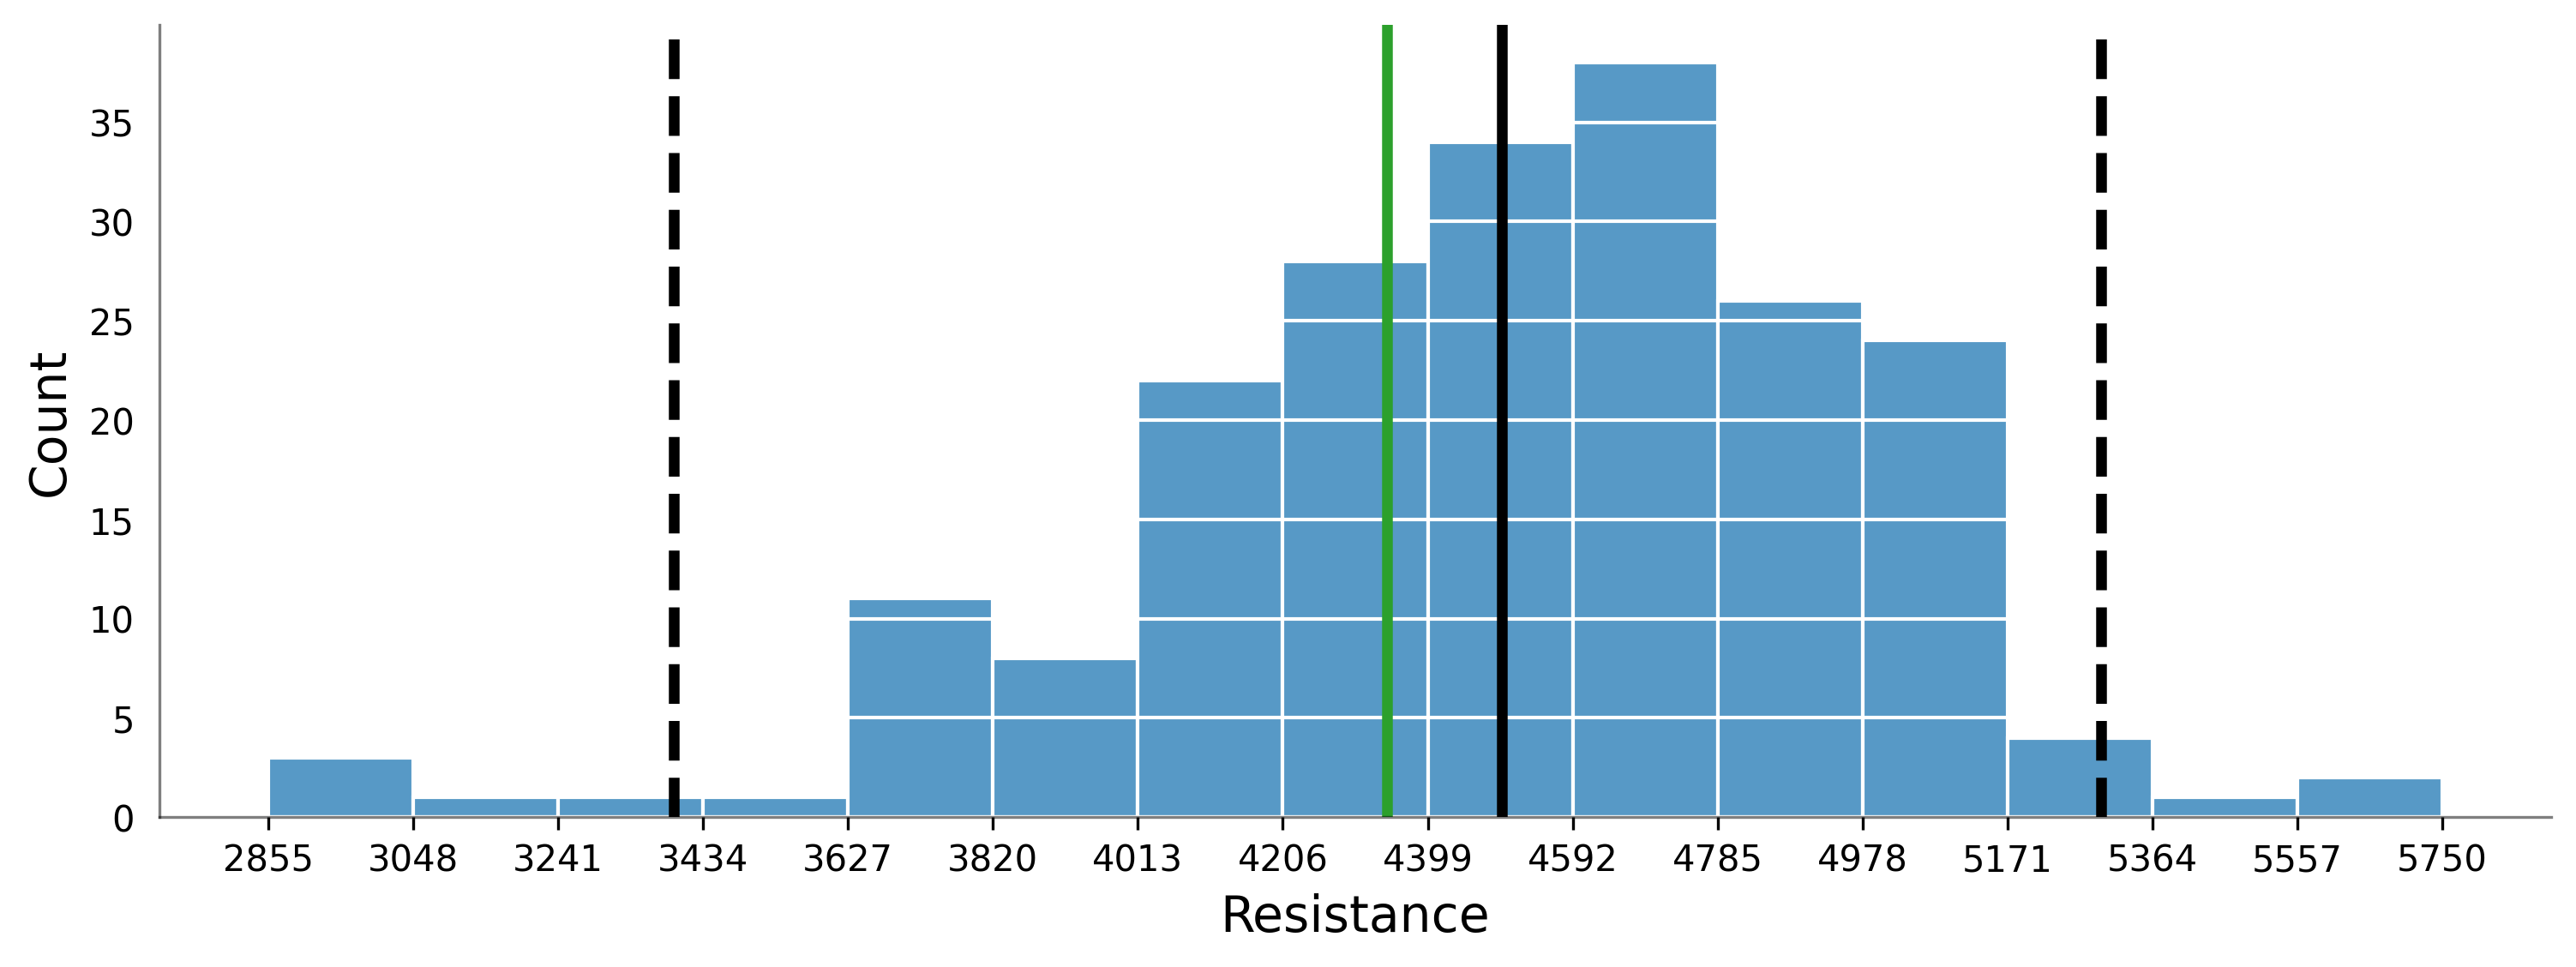

In [71]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(12,4), dpi=300)

# Plot data in histogram with bins='auto'
histplot = sns.histplot(initial_df['Resistance'], 
                        bins='auto', 
                        edgecolor='white')

ax.axvline(USL, ls='--', lw=3, c='black')
ax.axvline(LSL, ls='--', lw=3, c='black')
ax.axvline(target, ls='-', lw=3, c='tab:green')
ax.axvline(mean, ls='-', lw=3, c='black')

# Get bin edges from the plotted histogram
bin_edges = histplot.patches  # Access bars to infer bin edges

# Extract bin positions
if bin_edges:
    bins = np.array([patch.get_x() for patch in bin_edges] + [bin_edges[-1].get_x() + bin_edges[-1].get_width()])
    plt.xticks(bins)  # Set xticks to match bin edges

# Specify x Label and y label
plt.xlabel('Resistance', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Set the yticks and yticklabels to white
ax.tick_params(axis='y', color='white')

# Ensure that the y-grid is still visible
ax.yaxis.grid(True, color='white', linestyle='-', linewidth=1, zorder=1)  # Re-enable the y-grid

# Additional formatting
sns.despine()
ax.spines[['left','bottom']].set_alpha(0.5)

# Show plot
plt.show()

## Additional histogram

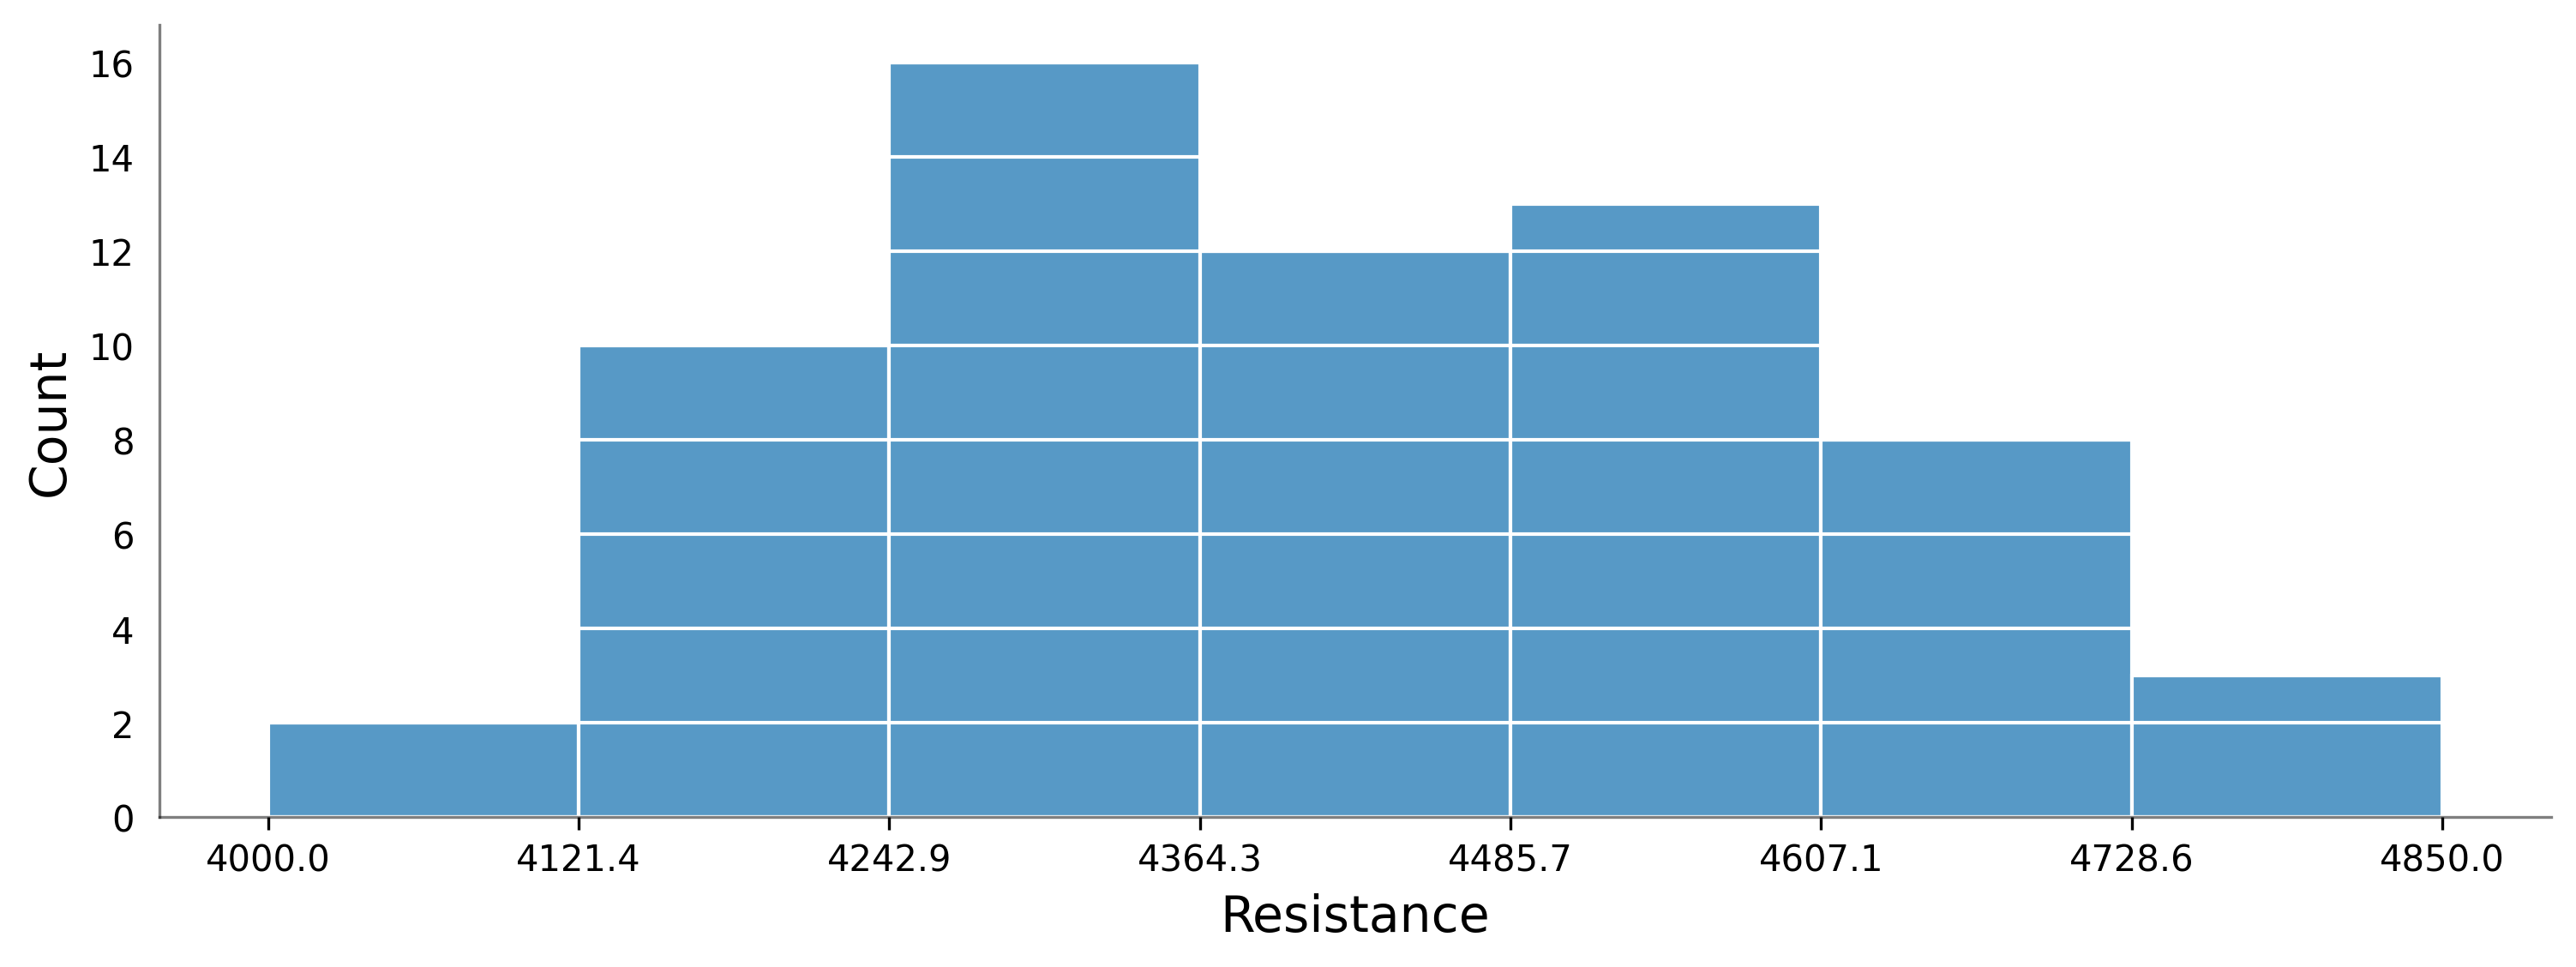

In [72]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(12,4), dpi=300)

# Plot data in histogram with bins='auto'
histplot = sns.histplot(additional_df['Resistance'], 
                        bins='auto', 
                        edgecolor='white')

# Get bin edges from the plotted histogram
bin_edges = histplot.patches  # Access bars to infer bin edges

# Extract bin positions
if bin_edges:
    bins = np.array([patch.get_x() for patch in bin_edges] + [bin_edges[-1].get_x() + bin_edges[-1].get_width()])
    plt.xticks(bins)  # Set xticks to match bin edges

# Specify x Label and y label
plt.xlabel('Resistance', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Set the yticks and yticklabels to white
ax.tick_params(axis='y', color='white')

# Ensure that the y-grid is still visible
ax.yaxis.grid(True, color='white', linestyle='-', linewidth=1, zorder=1)  # Re-enable the y-grid

# Additional formatting
sns.despine()
ax.spines[['left','bottom']].set_alpha(0.5)

# Show plot
plt.show()

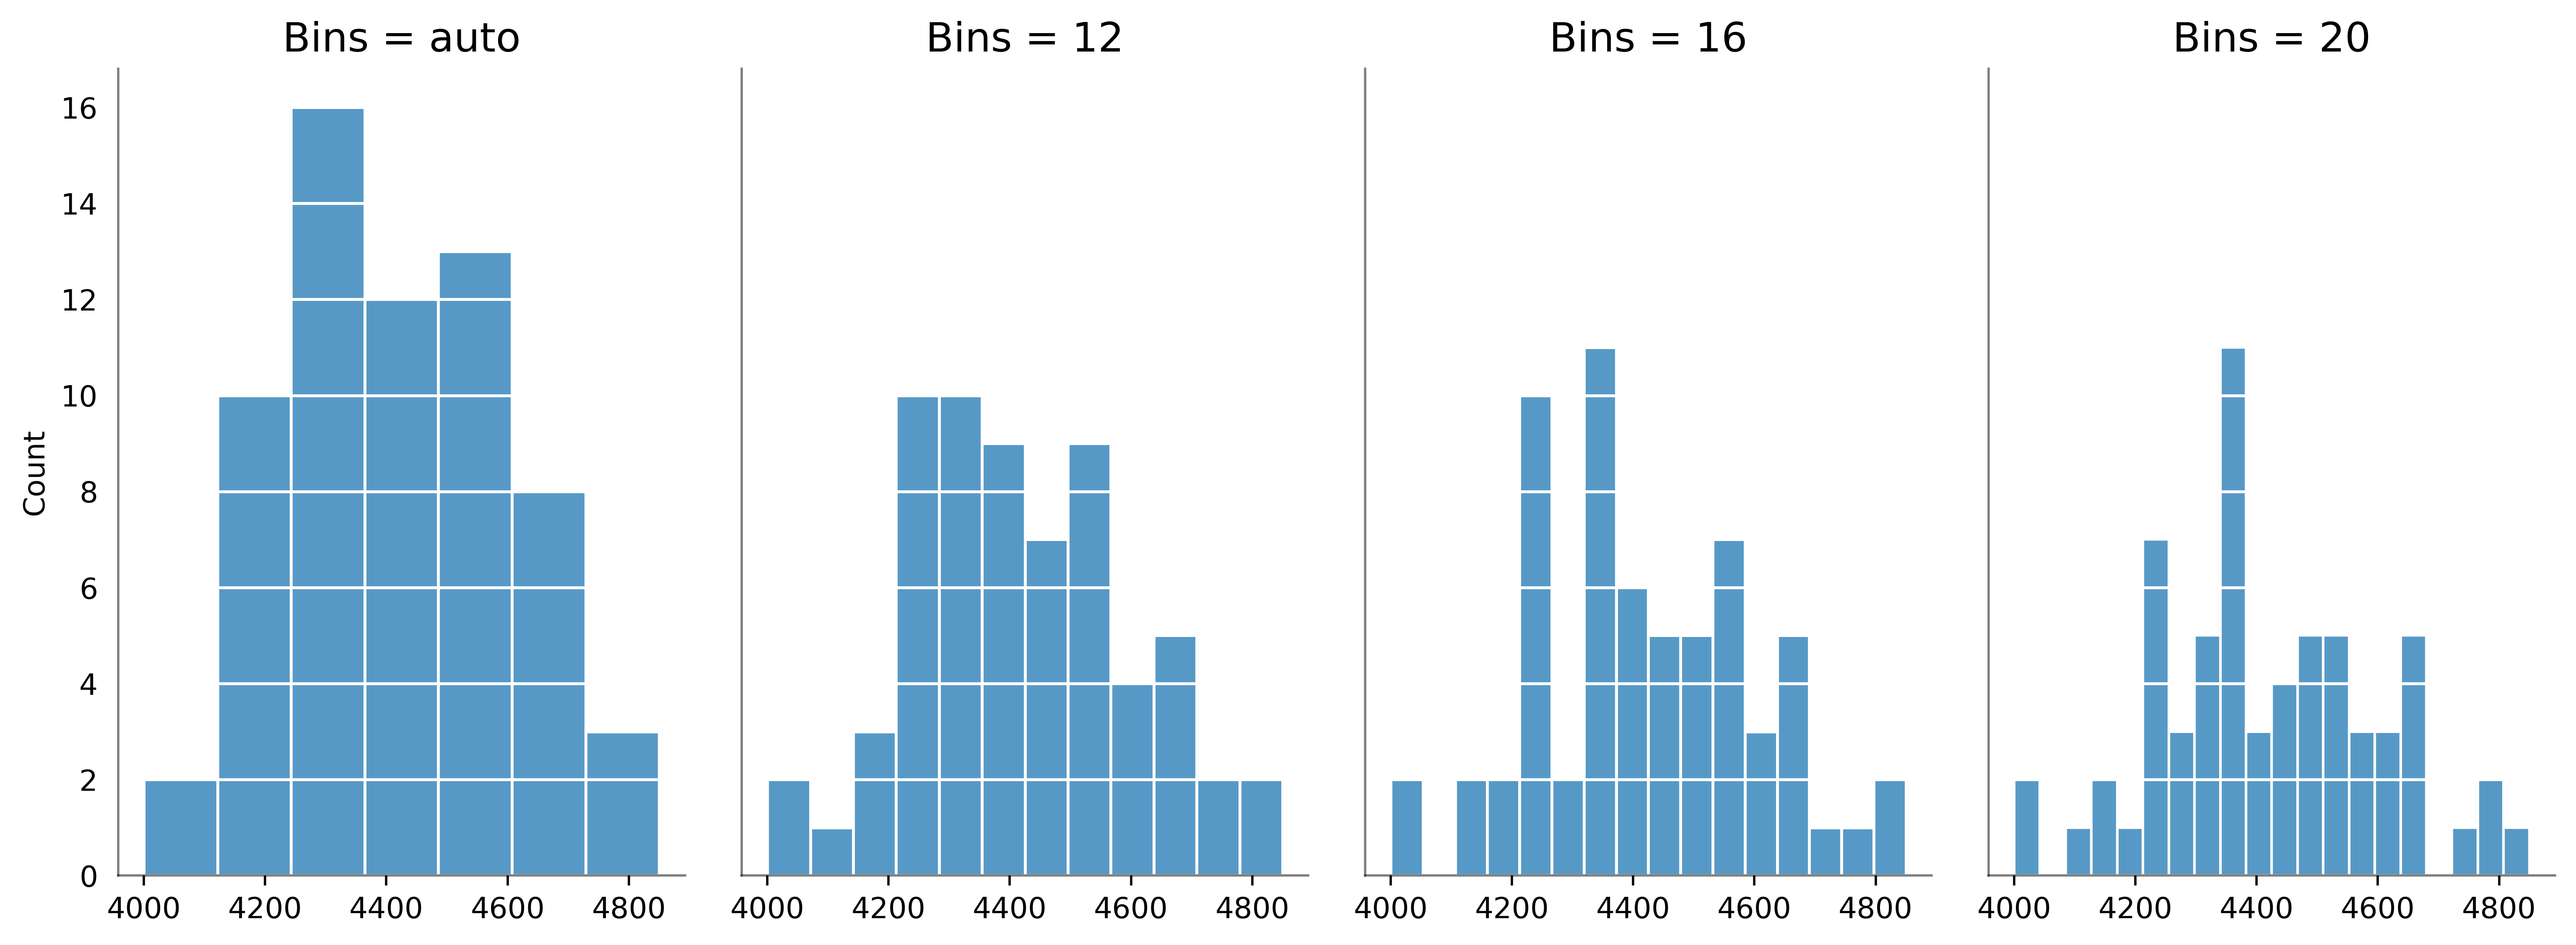

In [73]:
# Create figure and axis
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(15,5), 
                         sharey=True, dpi=500)
# Adjust white space of subplots
plt.subplots_adjust(wspace=0.1)

# List of bins for each subplot
bins_list = ['auto', 12, 16, 20]

# Loop over each subplot and bins value
for i, bins in enumerate(bins_list):
    sns.histplot(additional_df['Resistance'], 
                 bins=bins, 
                 ax=axes[i], 
                 edgecolor='white')
    axes[i].set_title(f'Bins = {bins}', fontsize=14)
    axes[i].set_xlabel('')
    axes[i].spines[['left','bottom']].set_alpha(0.5)
    # Set the yticks and yticklabels to white
    axes[i].tick_params(axis='y', color='white')
    # Ensure that the y-grid is still visible
    axes[i].yaxis.grid(True, color='white', linestyle='-', linewidth=1, zorder=1)  # Re-enable the y-grid

# Despine Figure
sns.despine()

# Show plot
plt.show()

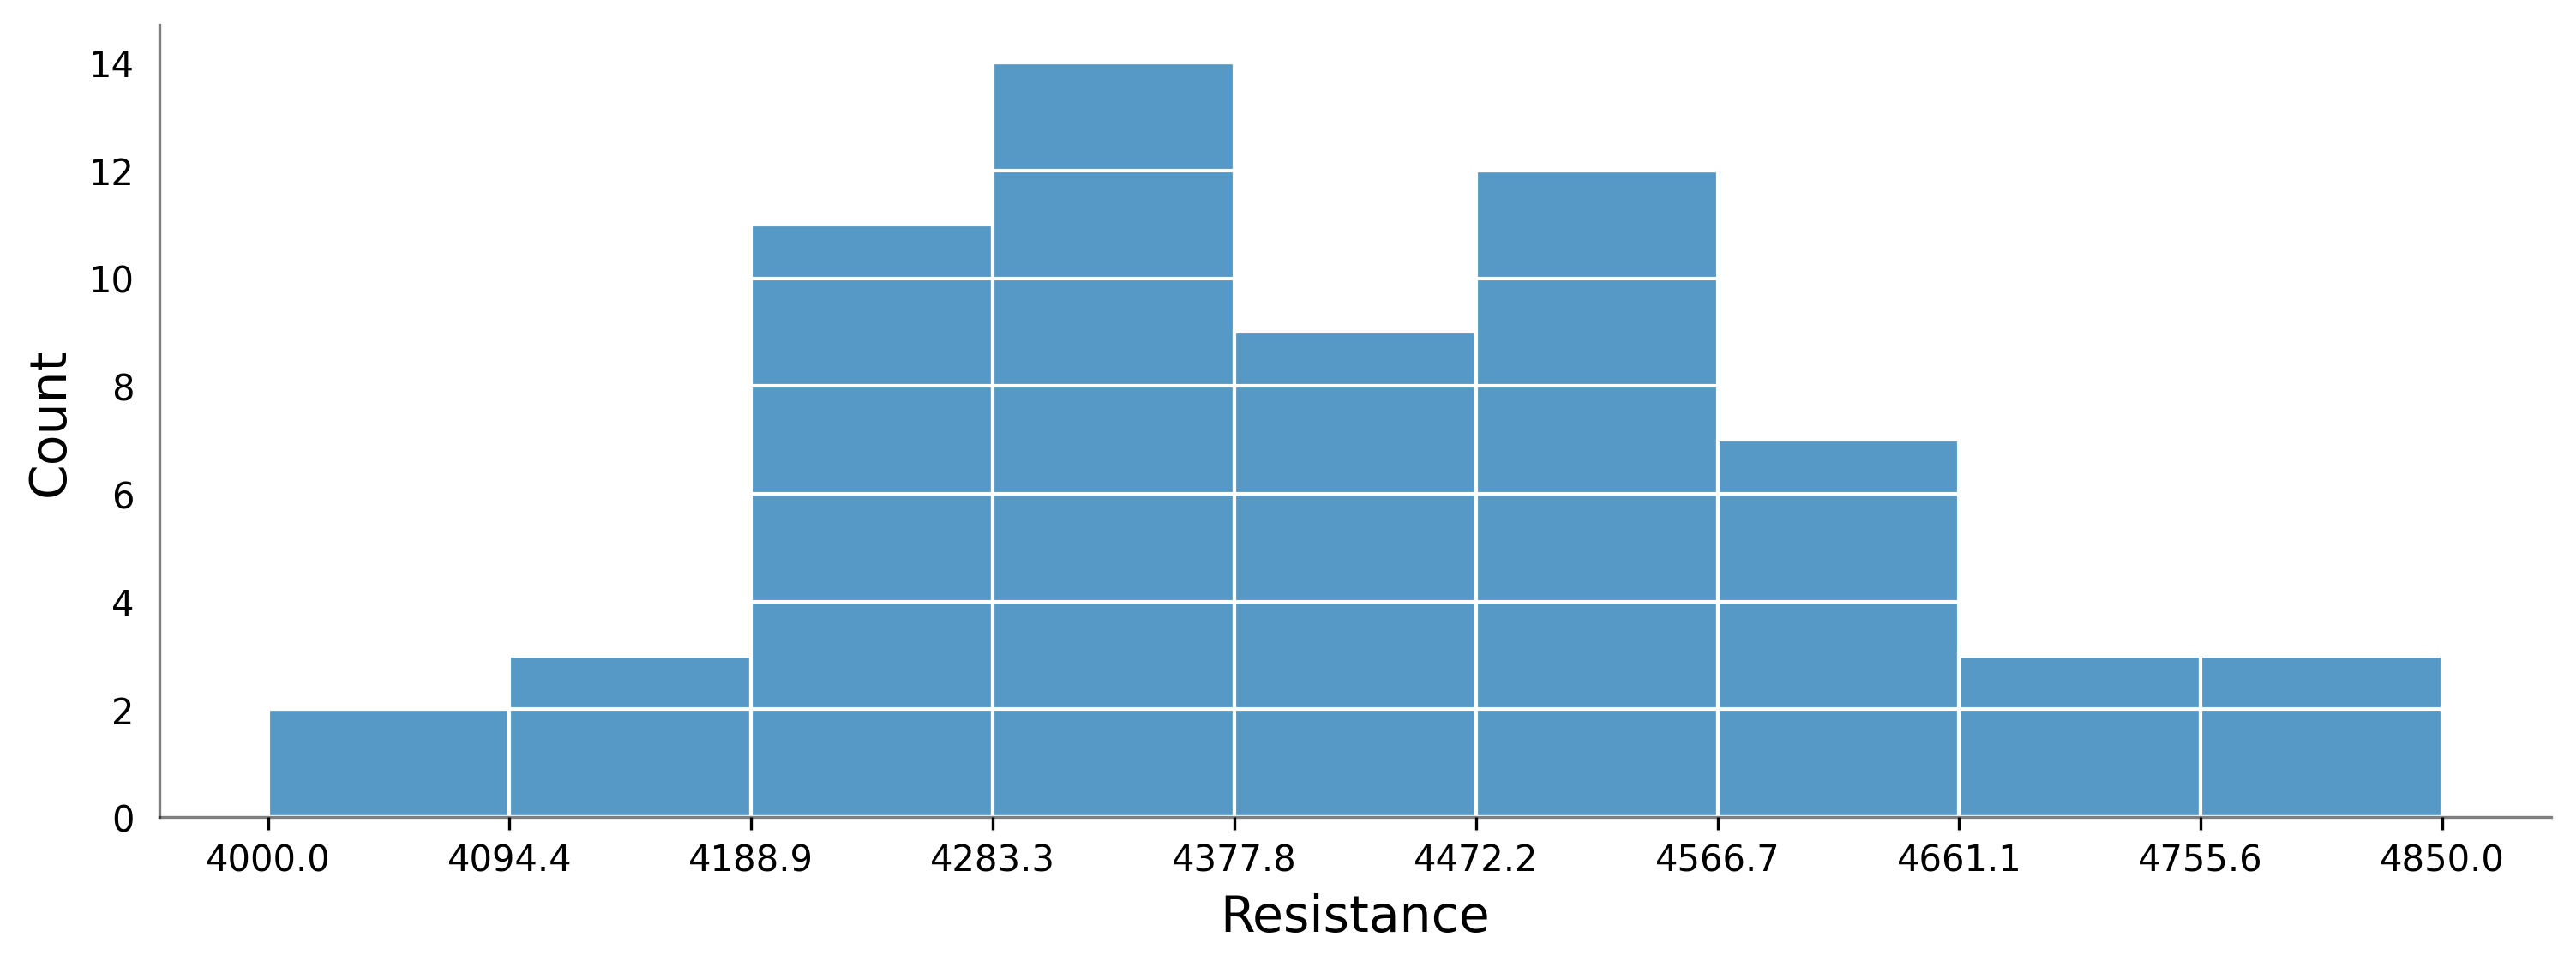

In [74]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(12,4), dpi=300)

# Plot data in histogram with bins='auto'
histplot = sns.histplot(additional_df['Resistance'], 
                        bins=9, 
                        edgecolor='white')

# Get bin edges from the plotted histogram
bin_edges = histplot.patches  # Access bars to infer bin edges

# Extract bin positions
if bin_edges:
    bins = np.array([patch.get_x() for patch in bin_edges] + [bin_edges[-1].get_x() + bin_edges[-1].get_width()])
    plt.xticks(bins)  # Set xticks to match bin edges

# Specify x Label and y label
plt.xlabel('Resistance', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Set the yticks and yticklabels to white
ax.tick_params(axis='y', color='white')

# Ensure that the y-grid is still visible
ax.yaxis.grid(True, color='white', linestyle='-', linewidth=1, zorder=1)  # Re-enable the y-grid

# Additional formatting
sns.despine()
ax.spines[['left','bottom']].set_alpha(0.5)

# Show plot
plt.show()

## Initial Time Series

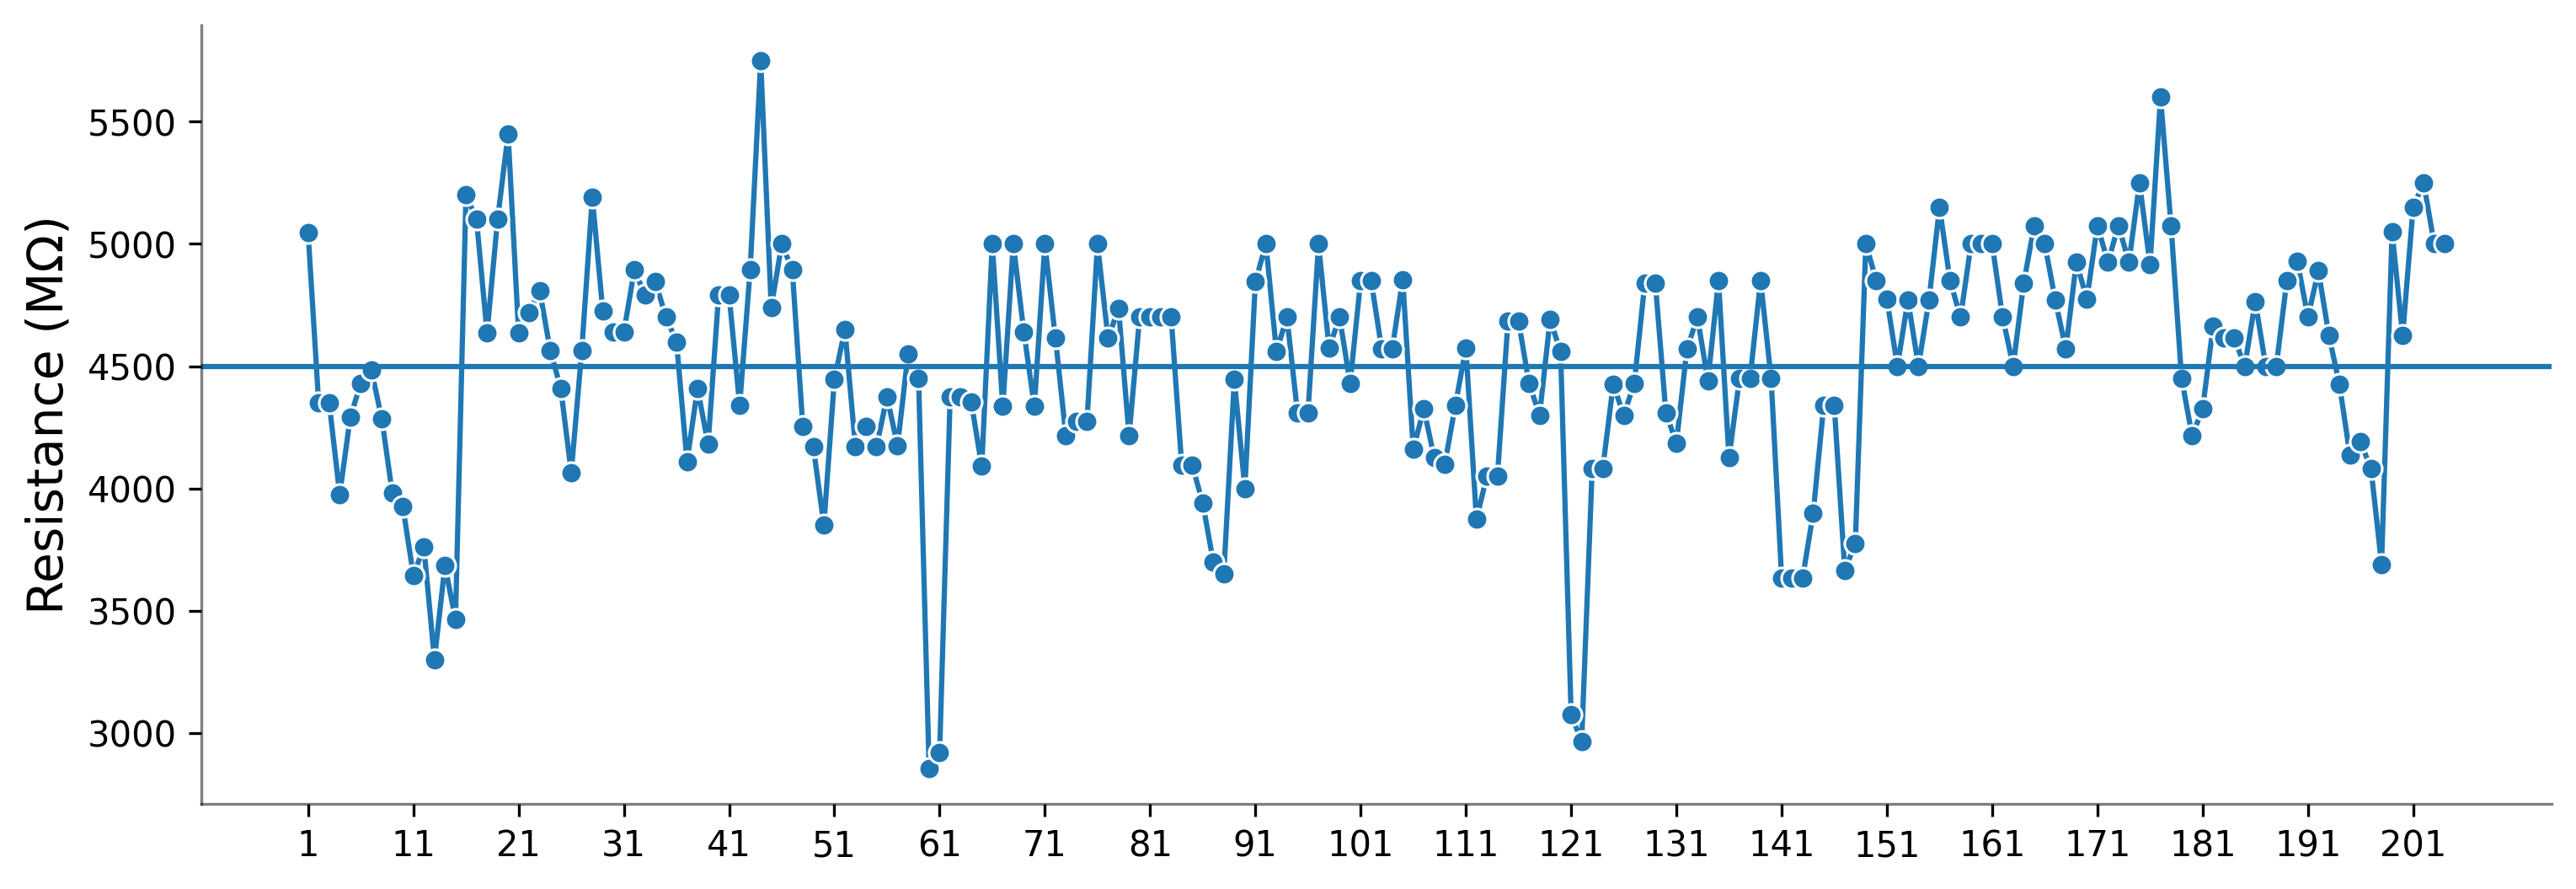

In [75]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(12,4), dpi=300)

# Plot data in lineplot
sns.lineplot(initial_df, 
             x='Value', 
             y='Resistance', 
             marker='o')

# Set the x-tick labels with increased intervals
labels = initial_df['Value']
tick_interval = 10
tick_positions = np.arange(0, len(labels), tick_interval)
ax.set_xticks(tick_positions)
ax.set_xticklabels(labels.iloc[tick_positions], rotation=0, ha='center') 

# Despine
sns.despine()
ax.spines[['left','bottom']].set_alpha(0.5)

# Additional formatting
ax.set_ylabel('Resistance (MΩ)', fontsize=14)
ax.set_xlabel('')

ax.axhline(mean)

# Show plot
plt.show()

## Additional Time Series

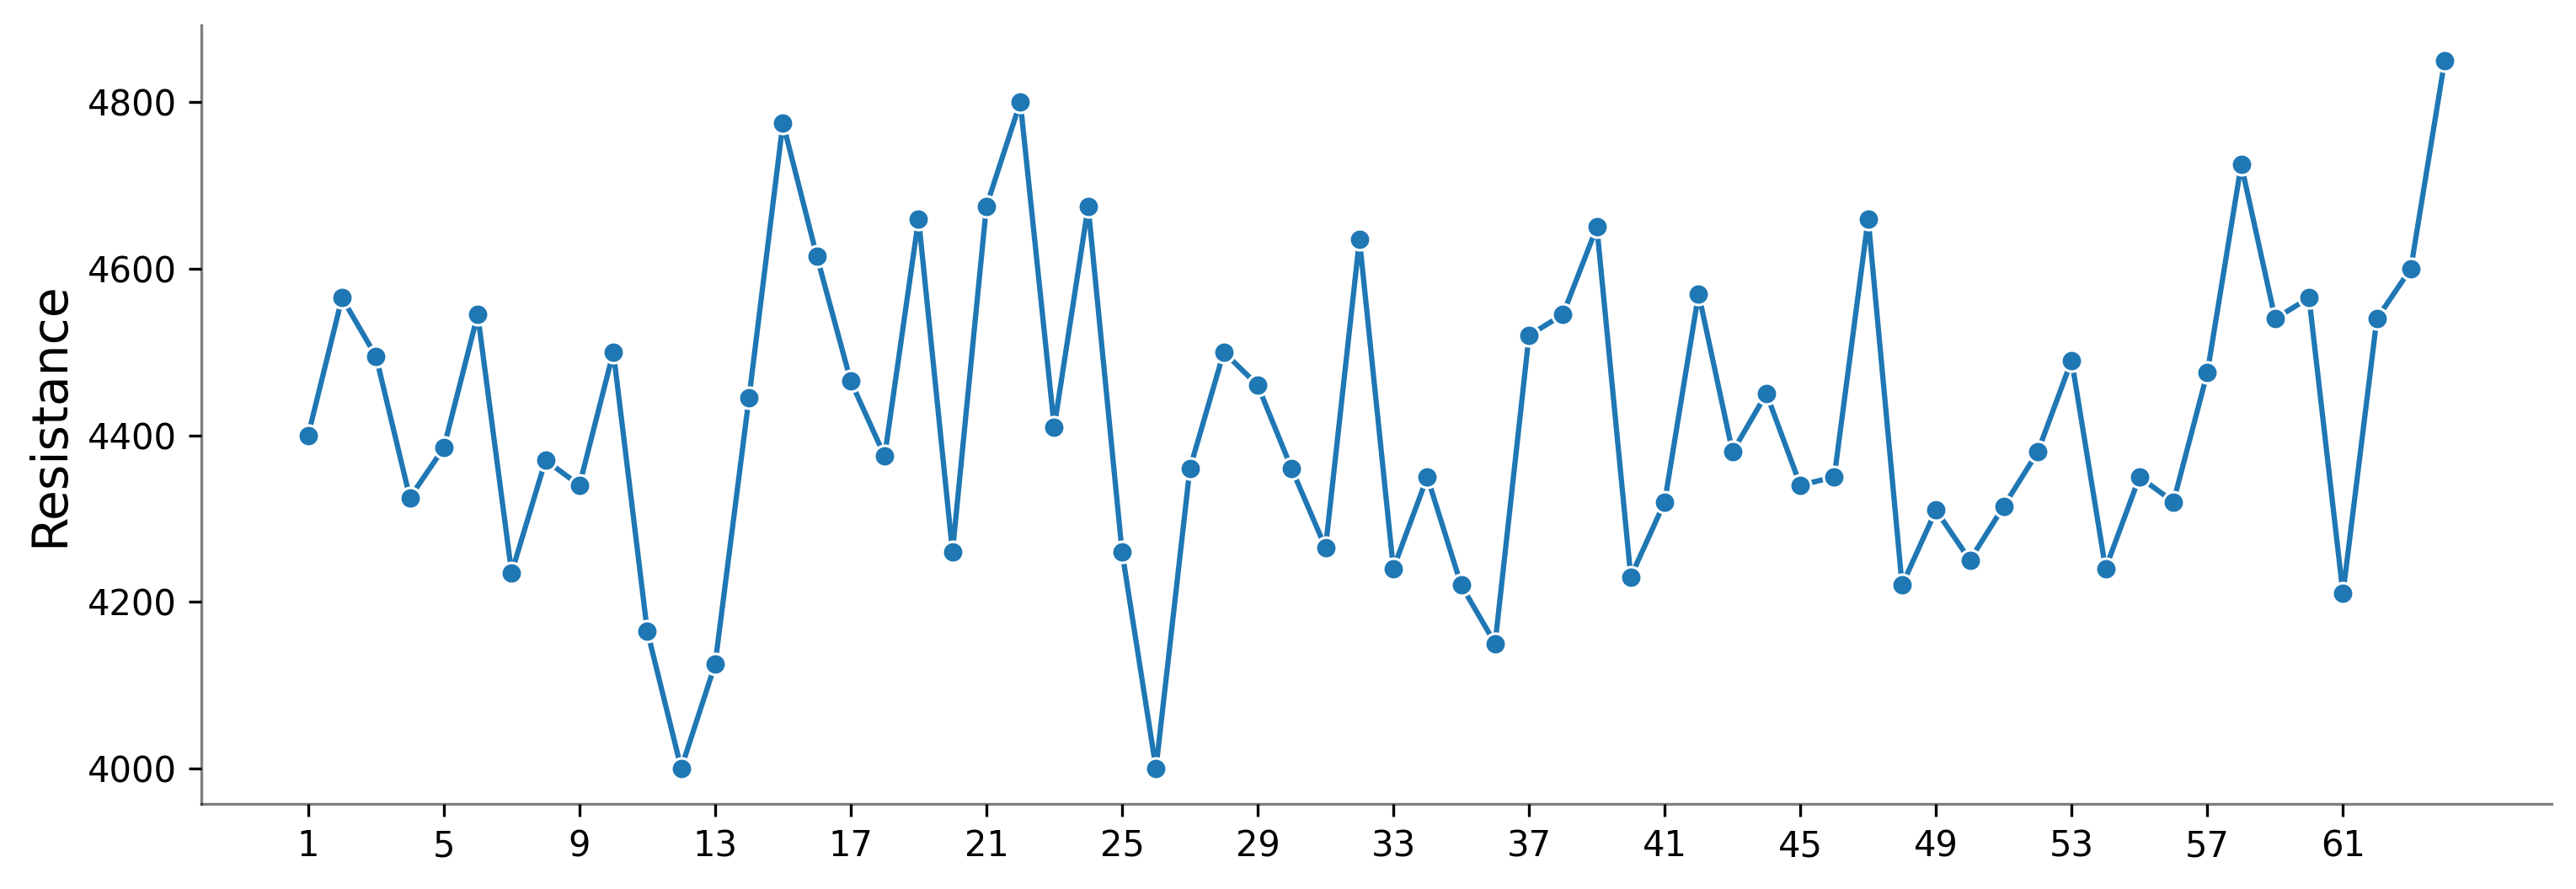

In [76]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(12,4), dpi=300)

# Plot data in lineplot
sns.lineplot(additional_df, 
             x='Value', 
             y='Resistance', 
             marker='o')

# Set the x-tick labels with increased intervals
labels = additional_df['Value']
tick_interval = 4
tick_positions = np.arange(0, len(labels), tick_interval)
ax.set_xticks(tick_positions)
ax.set_xticklabels(labels.iloc[tick_positions], rotation=0, ha='center') 

# Despine
sns.despine()
ax.spines[['left','bottom']].set_alpha(0.5)

# Additional formatting
ax.set_ylabel('Resistance', fontsize=14)
ax.set_xlabel('')
    
# Show plot
plt.show()

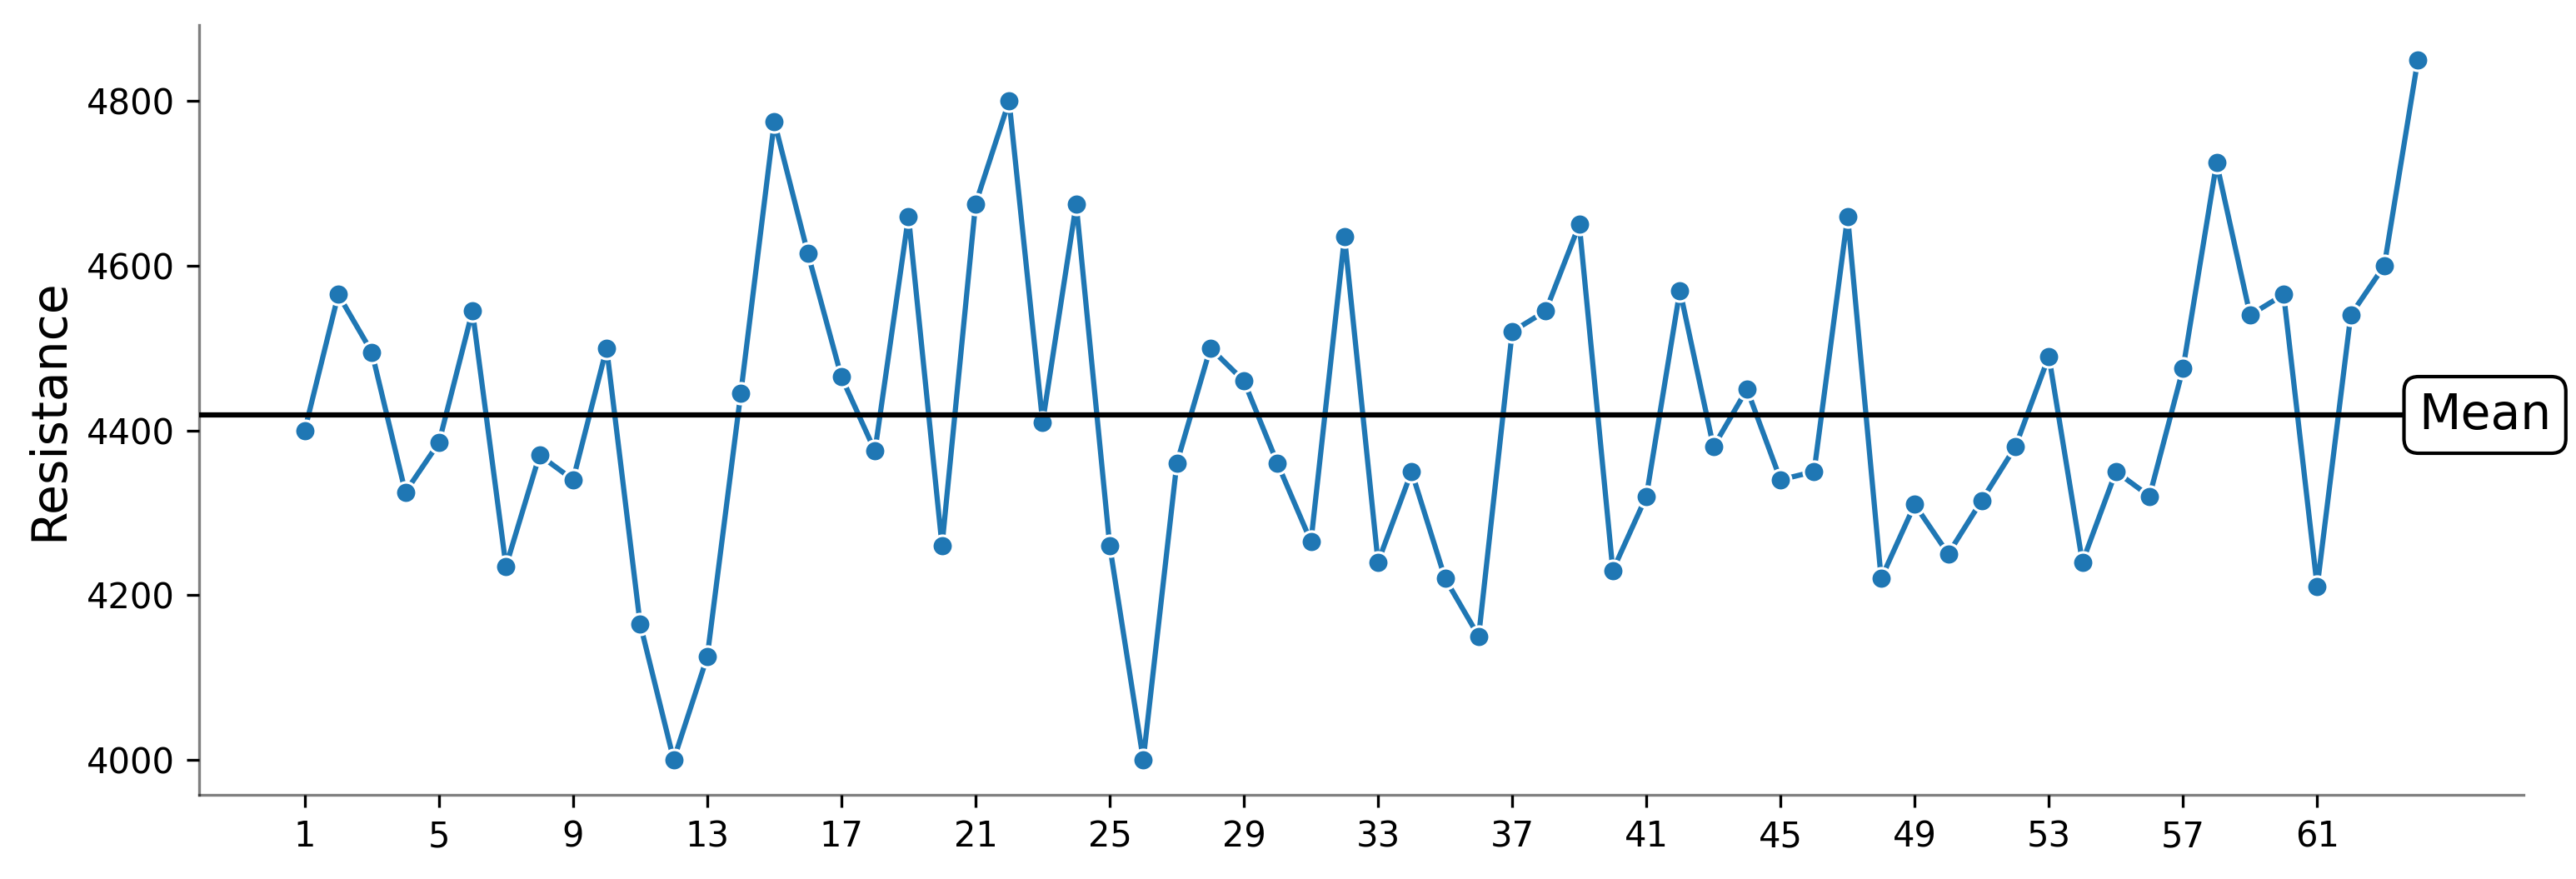

In [77]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(12,4), dpi=300)

# Plot data in lineplot
sns.lineplot(additional_df, 
             x='Value', 
             y='Resistance', 
             marker='o')

# Plot the mean
ax.axhline(additional_df['Resistance'].mean(), c='black')
ax.annotate("Mean",
            xy=(65,additional_df['Resistance'].mean()),
            ha='center',
            va='center',
            fontsize=14,
           bbox=dict(facecolor='white', edgecolor='black', boxstyle='Round'),
           )

# Set the x-tick labels with increased intervals
labels = additional_df['Value']
tick_interval = 4
tick_positions = np.arange(0, len(labels), tick_interval)
ax.set_xticks(tick_positions)
ax.set_xticklabels(labels.iloc[tick_positions], rotation=0, ha='center') 

# Despine
sns.despine()
ax.spines[['left','bottom']].set_alpha(0.5)

# Additional formatting
ax.set_ylabel('Resistance', fontsize=14)
ax.set_xlabel('')
    
# Show plot
plt.show()

## Initial XmR chart

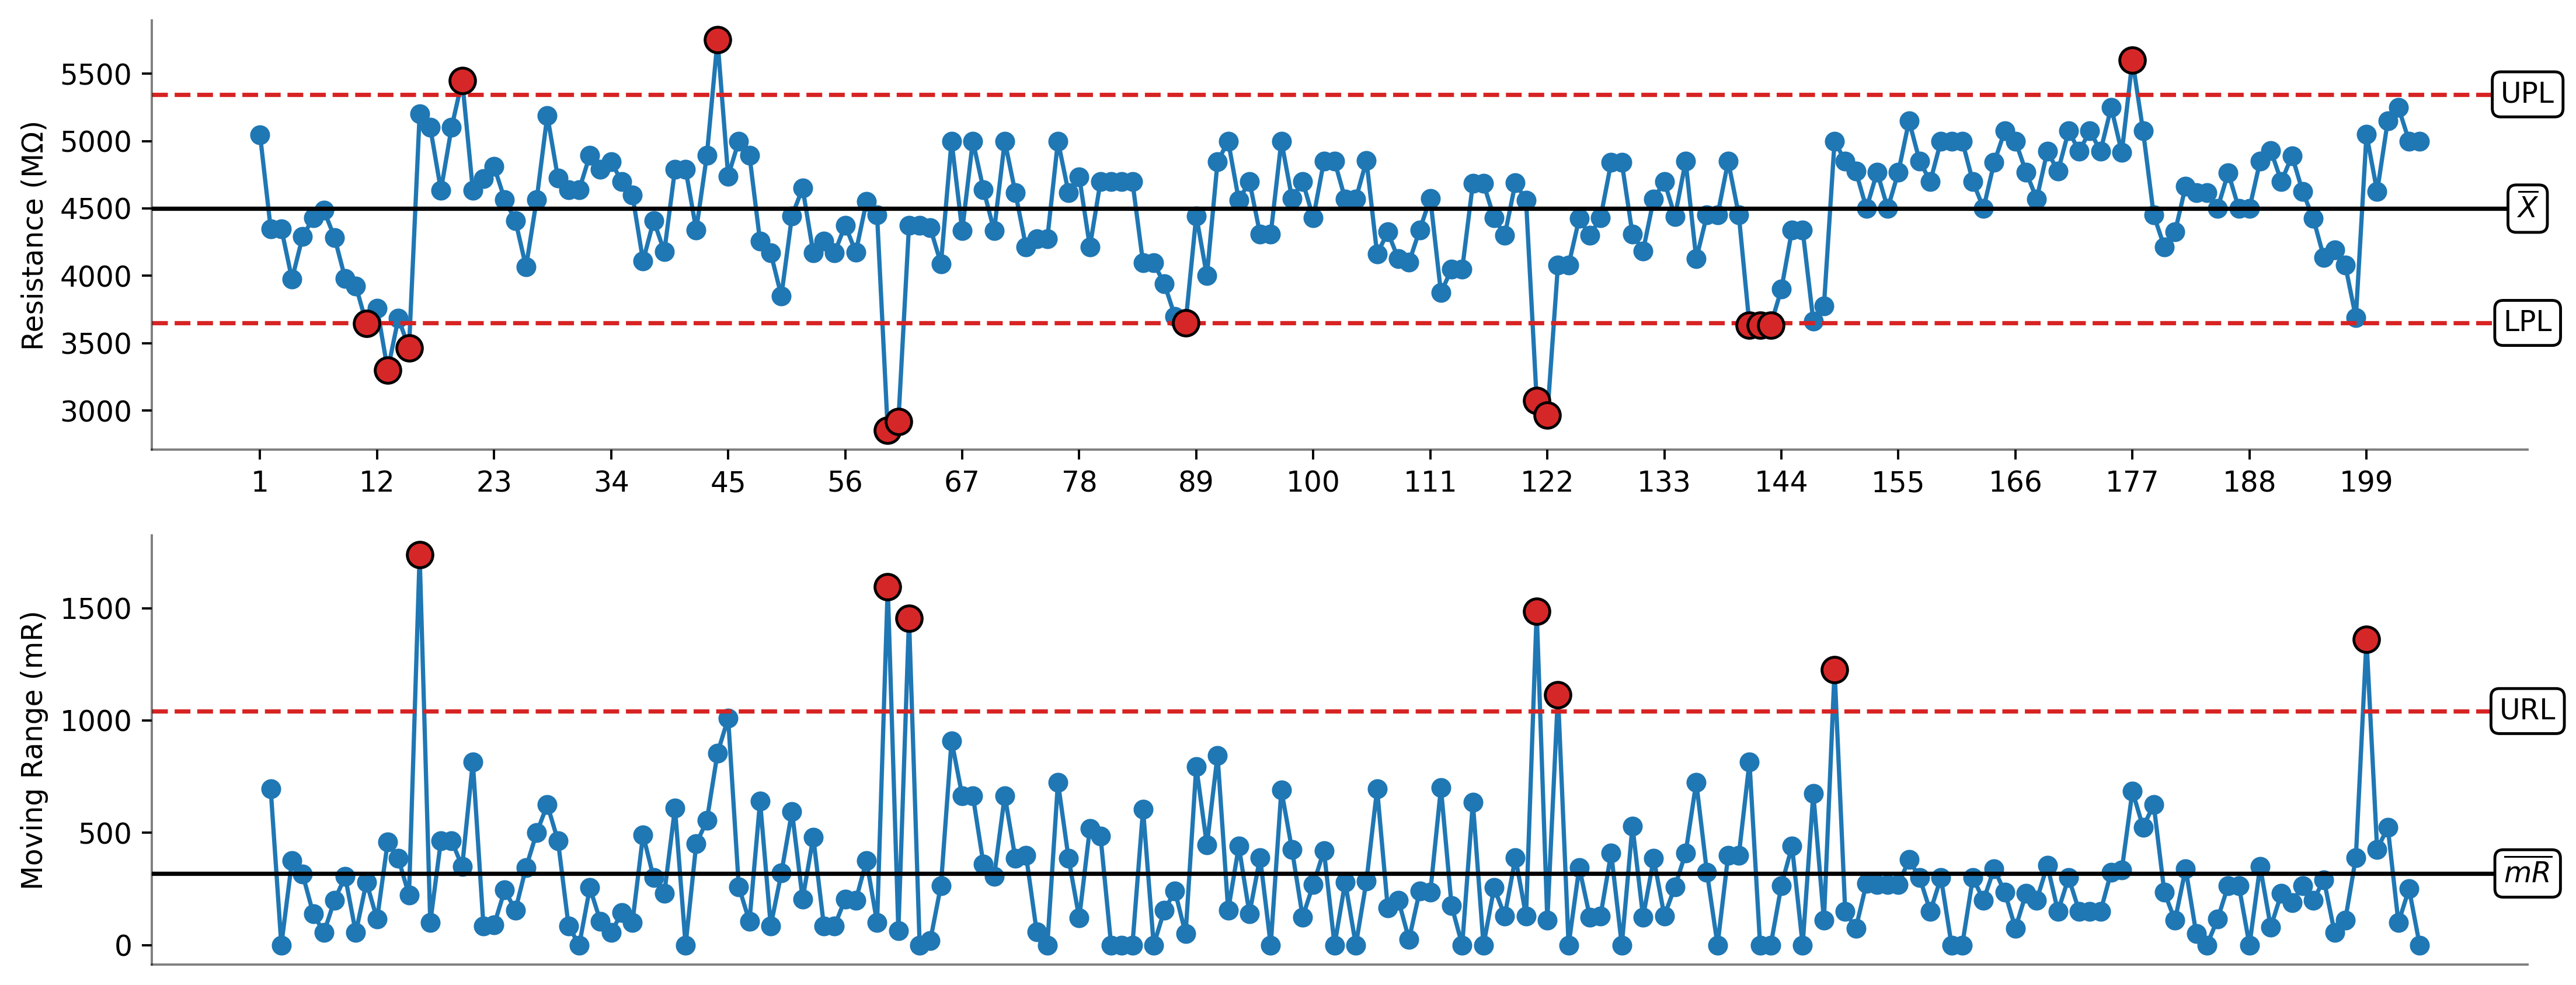

In [78]:
# XmR chart configuration
config = XmRChartConfig(
    tickinterval=11,
    round_value=1,
    show_xticks=True,
    show_yticks=True,
    show_limit_values=False,
    xchart_ylabel="Resistance (MΩ)"
)

# Create XmR chart
results = xmr_chart(
    initial_df, 
    'Resistance', 
    'Value', 
    config=config
)

## Additional XmR chart

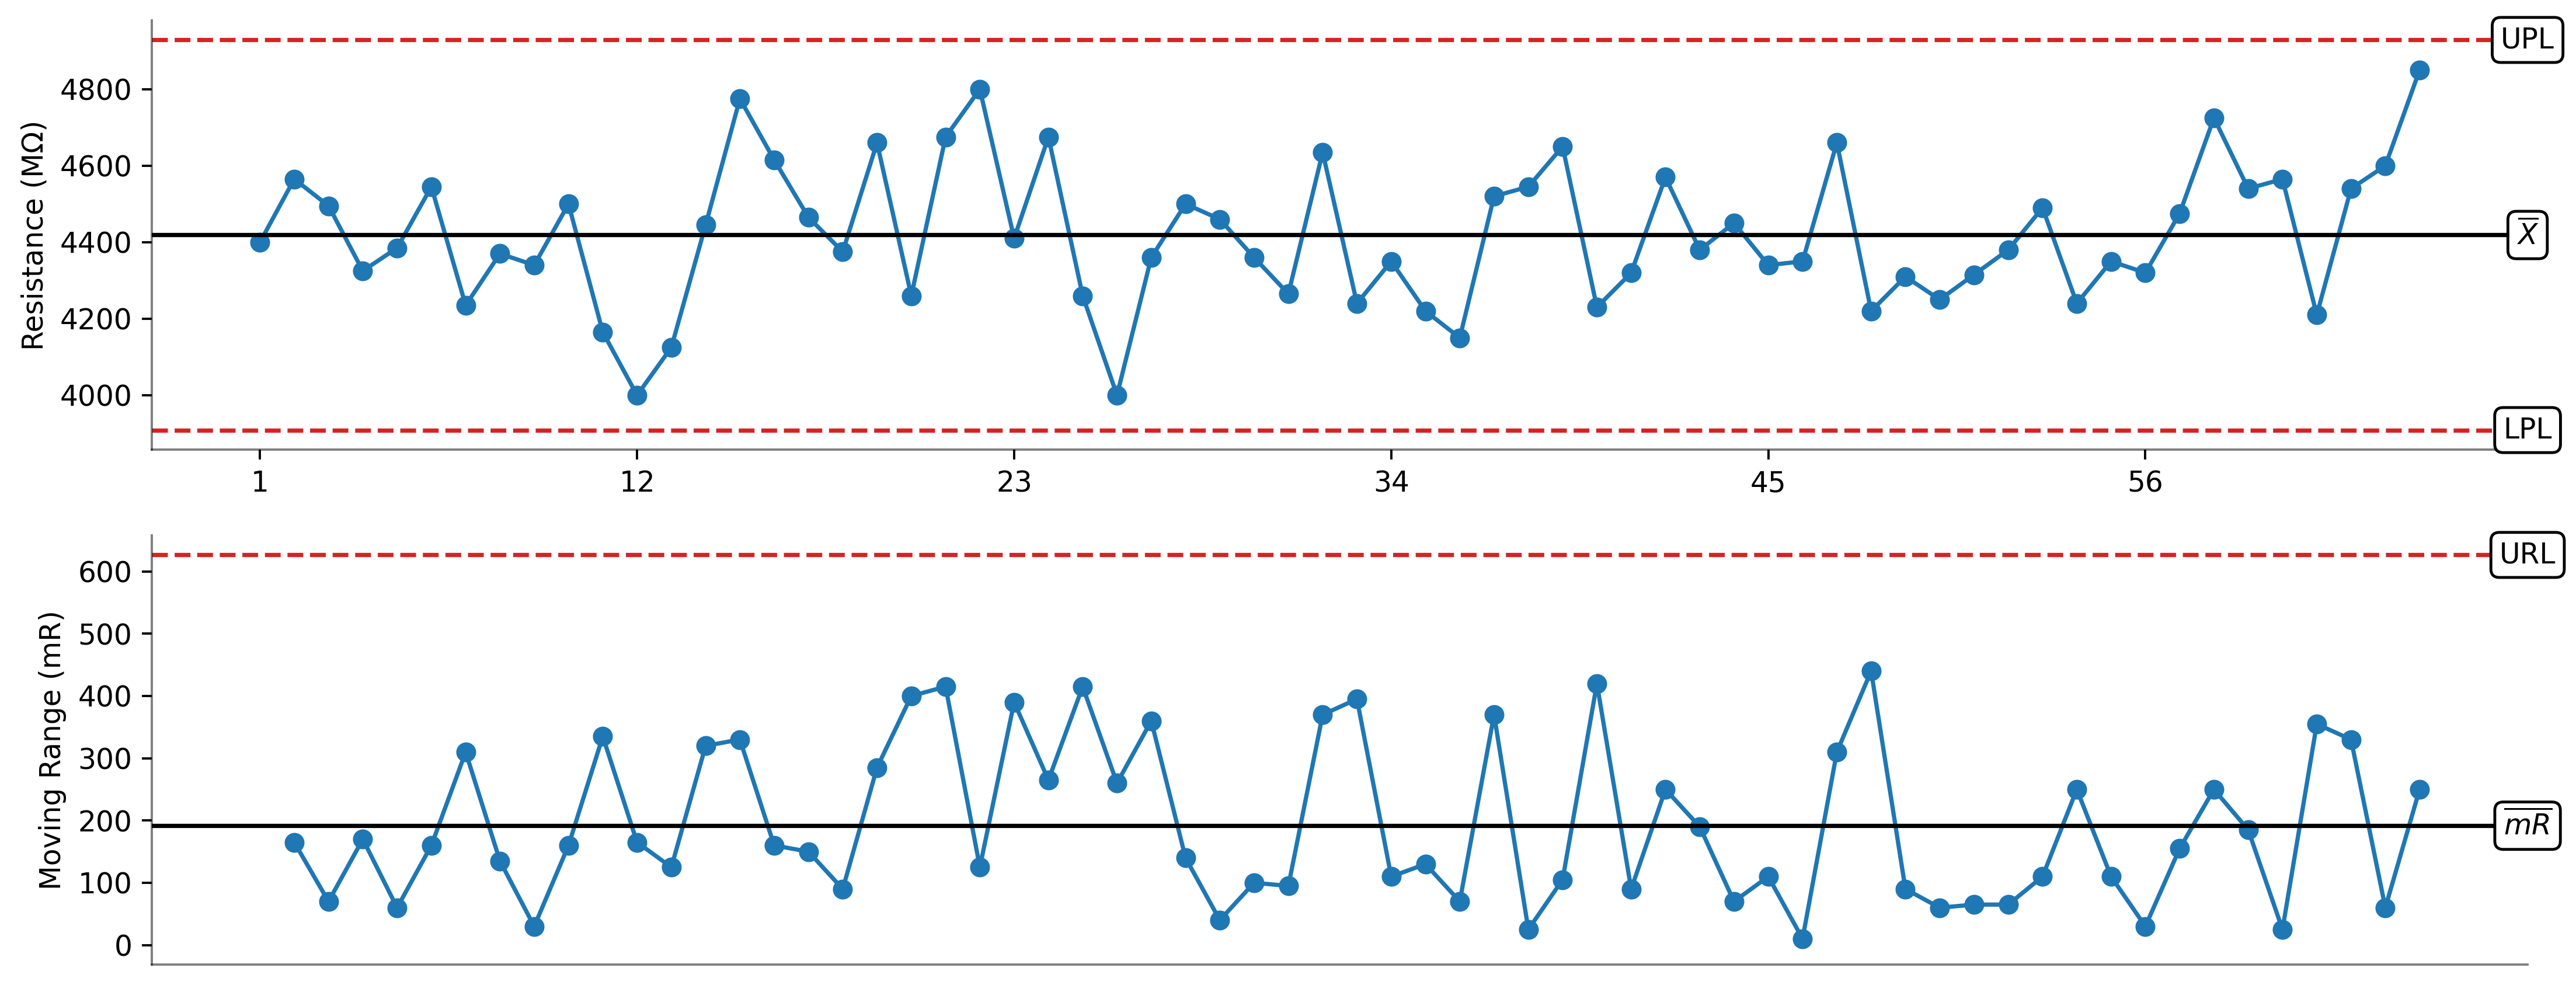

In [79]:
# XmR chart configuration
config = XmRChartConfig(
    tickinterval=11,
    round_value=1,
    show_xticks=True,
    show_yticks=True,
    show_limit_values=False,
    xchart_ylabel="Resistance (MΩ)"
)

# Create XmR chart
results = xmr_chart(
    additional_df, 
    'Resistance', 
    'Value', 
    config=config
)

## Comparison

In [80]:
# Create list of resistance dataframes
shewhart_list = [initial_df, additional_df]

# Create label_list
label_list = ['Unpredictable process', 'Predictable process']
label_list = ['','']

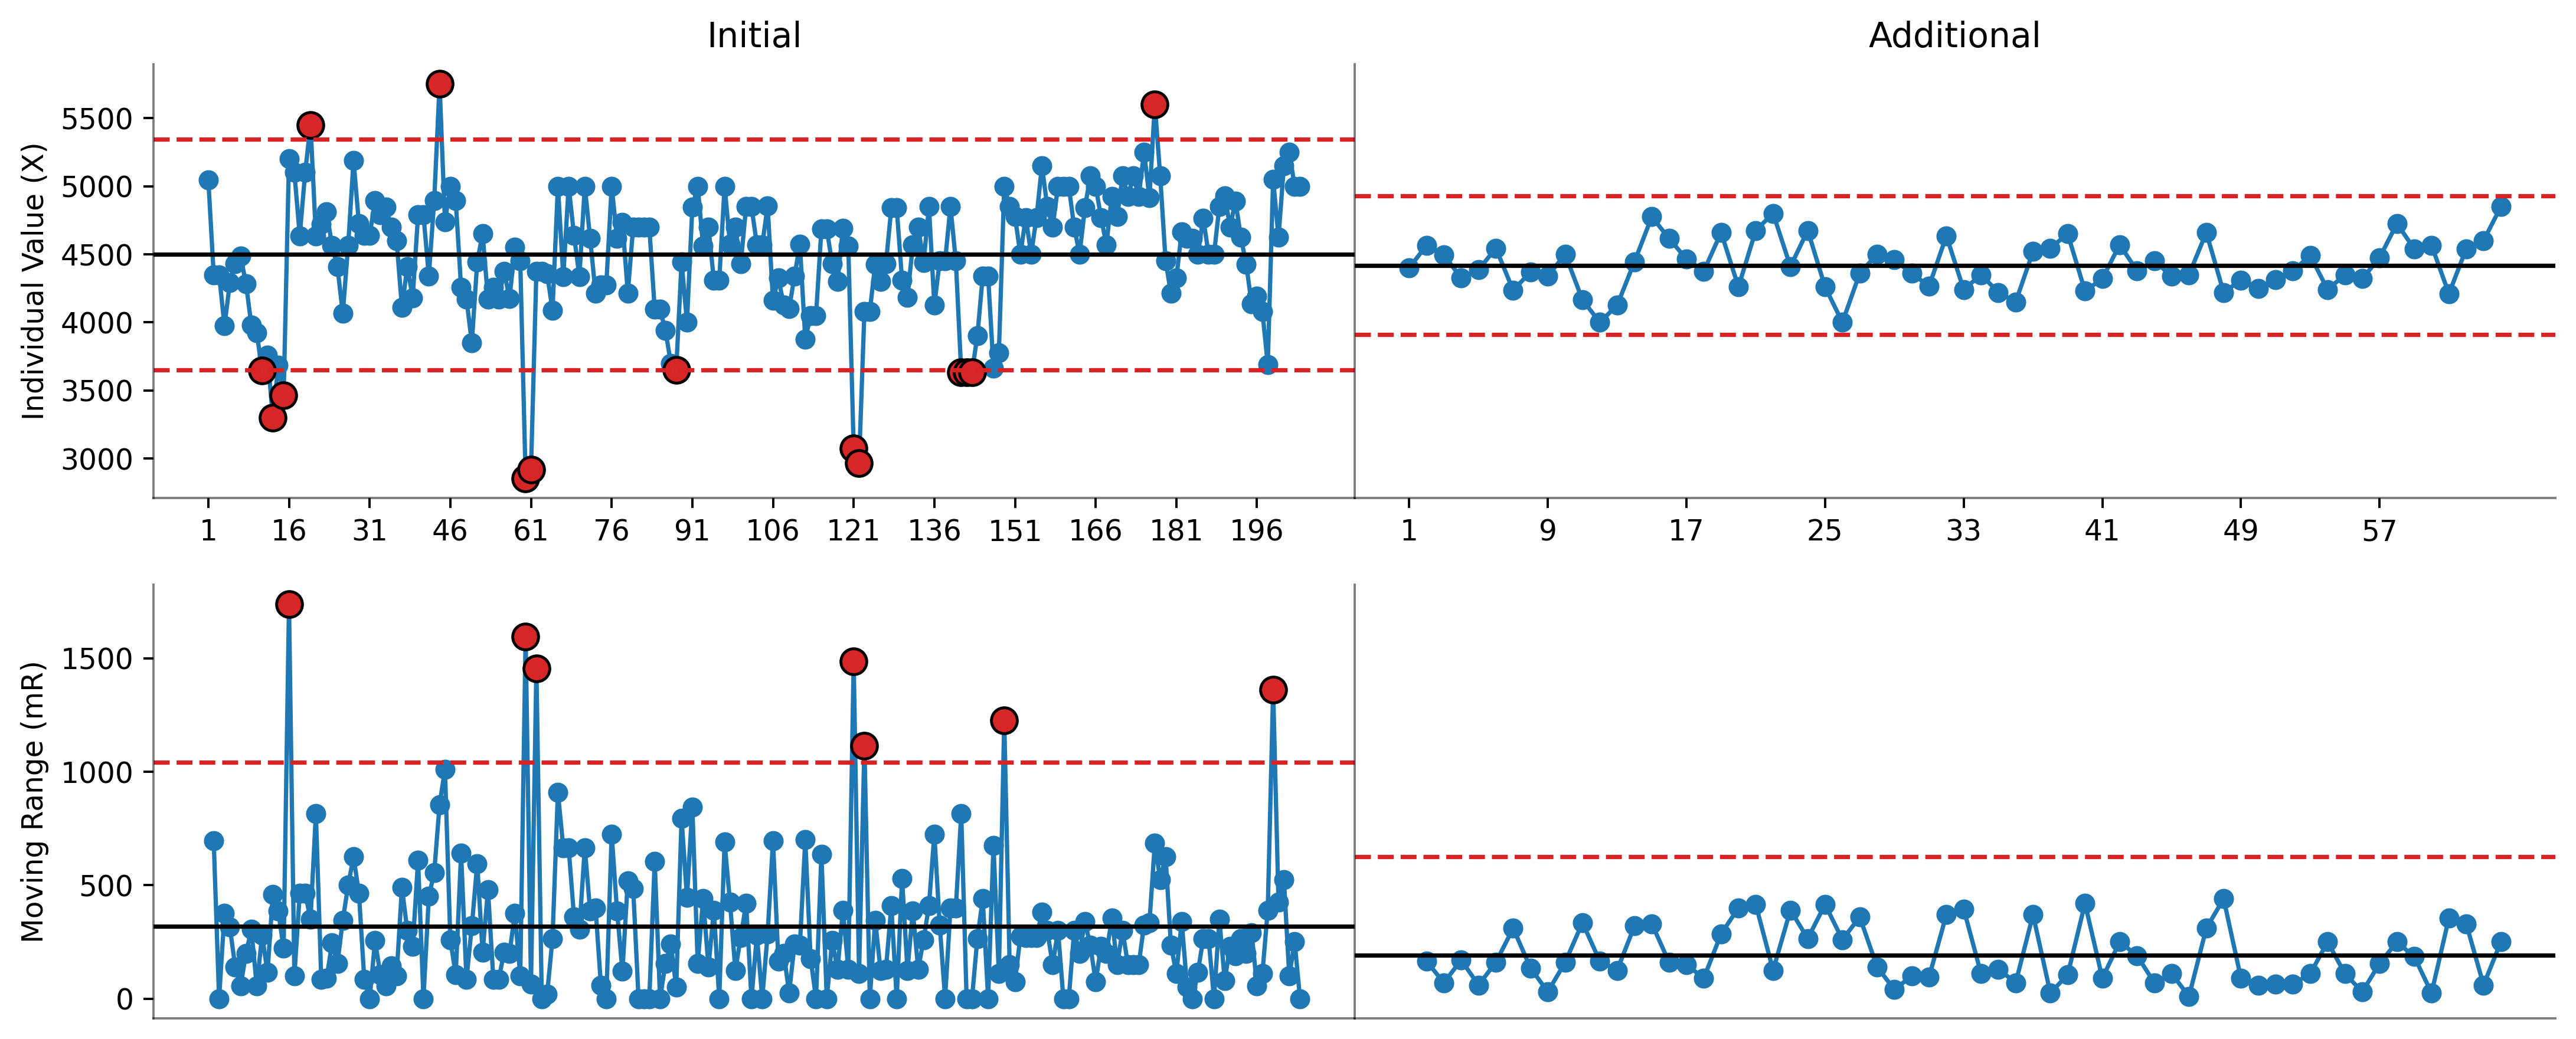

In [81]:
config = XmRCompConfig(
    figsize=(15,5),
    dpi=300
)

comparison_results = xmr_comparison(
    df_list = [initial_df, additional_df],
    values = 'Resistance',
    x_labels = 'Value',
    tickintervals=[15,8],
    subplot_titles = ['Initial', 'Additional']
)

## Detective work

In [82]:
# Create empty dataframe
empty_df = pd.DataFrame()
empty_df['Value'] = pd.Series(dtype='float64')
empty_df['Resistance'] = pd.Series(dtype='float64')

# Create list of resistance dataframes
df_list = [initial_df, empty_df, additional_df]

# Create label_list
label_list = ['Unpredictable process', '', 'Predictable process']

In [83]:
# Constants for control limits
E2 = 2.660
D4 = 3.268

# Specify dataframe column as condition
condition = 'Resistance'
x_labels = 'Value' 

# Helper function to calculate statistics and limits
def calculate_limits(df, condition):
    mean = df[condition].mean()
    diff_amr = abs(df[condition].diff()).mean()
    UPL = mean + E2 * diff_amr
    LPL = max(mean - E2 * diff_amr, 0)
    URL = D4 * diff_amr
    return mean, diff_amr, UPL, LPL, URL

# Calculate statistics
stats = [calculate_limits(df, condition) for df in df_list]

# Isolate column to be used for x_labels
x_labels_for_plots = [df[x_labels] for df in df_list]

# Create results dataframe
parameters_df = pd.DataFrame(stats, columns=[r'$overline{x}$', 'AmR', 'UPL', 'LPL', 'URL'])
parameters_df['Labels'] = label_list
parameters_df['PLR'] = parameters_df['UPL'] - parameters_df['LPL']
parameters_df['data'] = [df[condition] for df in df_list]
parameters_df['mR'] = [abs(df[condition].diff()) for df in df_list]

# Determine predictability
parameters_df['Characterization'] = parameters_df.apply(
    lambda row: 'Predictable' if all(row['LPL'] <= x <= row['UPL'] for x in row['data']) else 'Unpredictable',
    axis=1
)

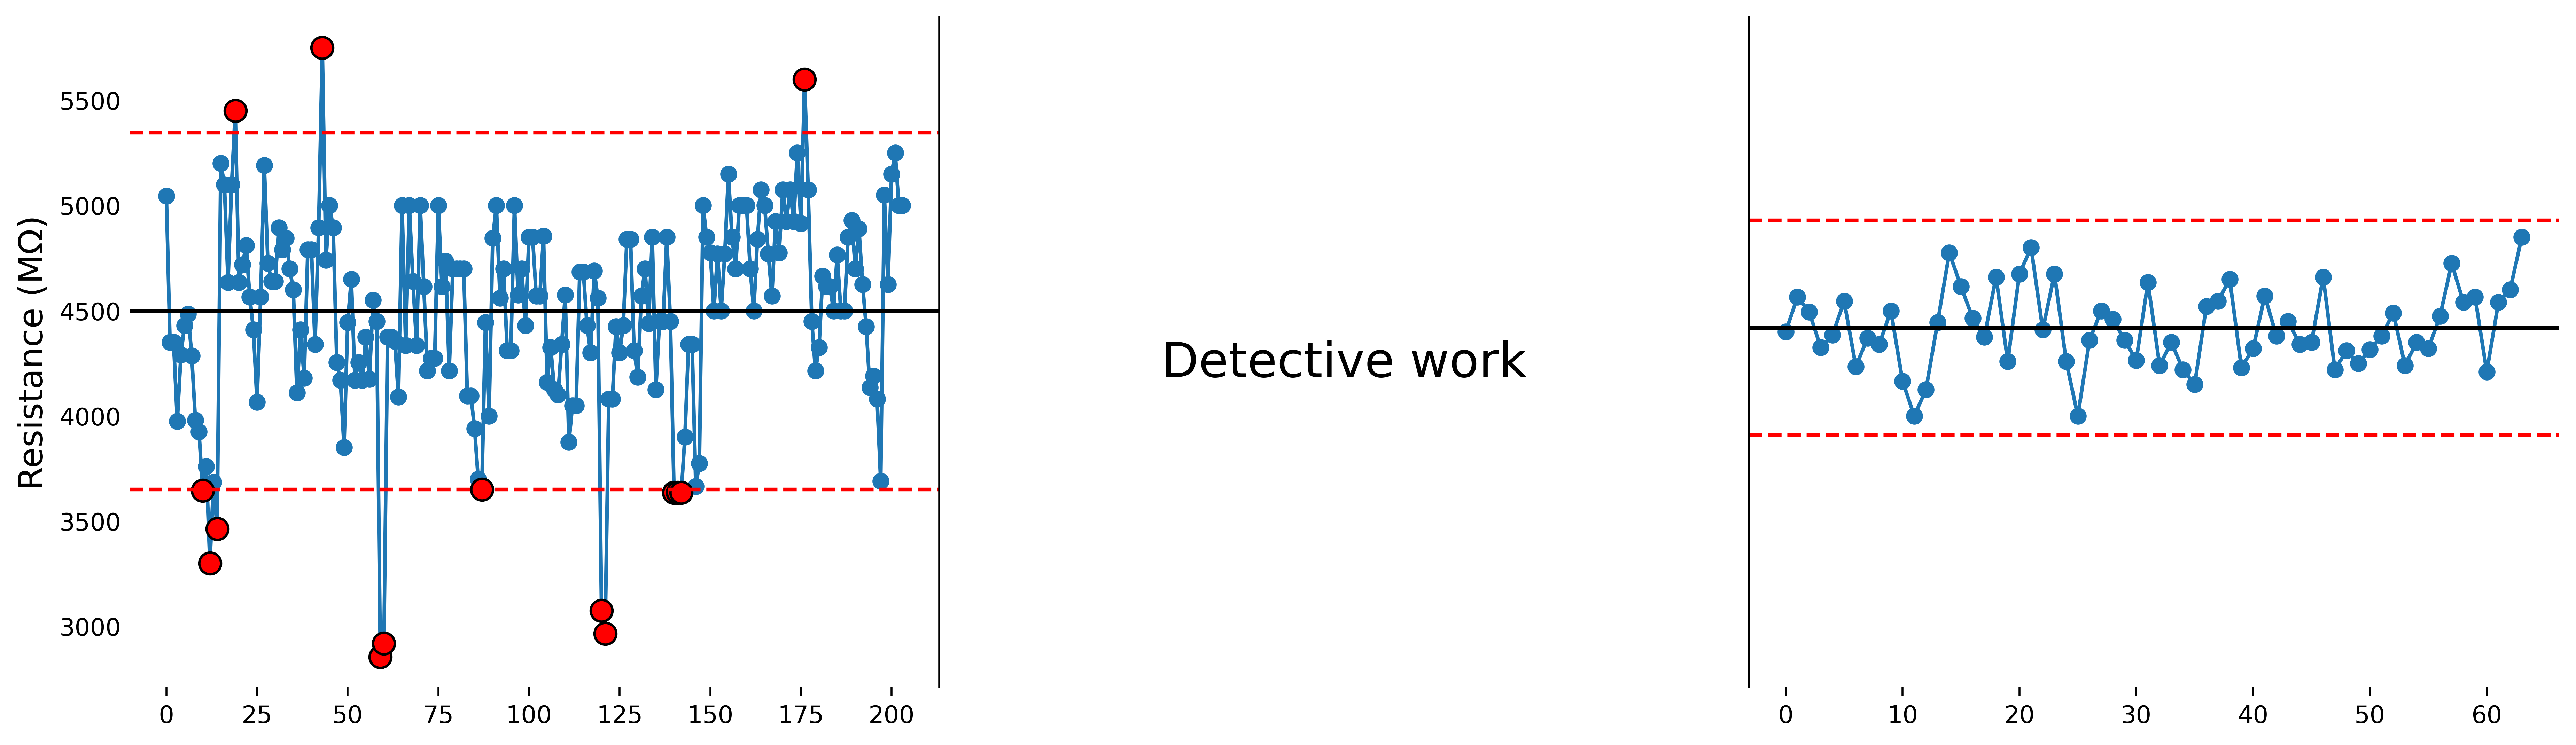

In [84]:
# Create figure and axes
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18,5), sharey=True, dpi=500)
plt.subplots_adjust(wspace=0)
gs = gridspec.GridSpec(1, 3, width_ratios=[2, 1, 2])

# Flatten the axes
axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]

# Plot each dataset
for idx, (data, UPL, LPL, label, ax, x_labels) in enumerate(zip(
    parameters_df['data'], 
    parameters_df['UPL'], 
    parameters_df['LPL'], 
    parameters_df['Labels'], 
    axes,
    x_labels_for_plots)):

    # Plot data
    ax.plot(data, marker='o', ls='-')

    # Masking and plotting limits
    ax.plot(np.ma.masked_where(data < UPL, data), marker='o', ls='none', color='red', markeredgecolor='black', markersize=9)
    ax.plot(np.ma.masked_where(data > LPL, data), marker='o', ls='none', color='red', markeredgecolor='black', markersize=9)

    # Plotting lines for mean, UPL, and LPL
    mean = np.mean(data)
    ax.axhline(mean, ls='-', color='black')
    ax.axhline(UPL, ls='--', color='red')
    ax.axhline(LPL, ls='--', color='red')

    # Styling axes
    ax.grid(False)
#     ax.set_title(label, fontsize=16)
    # Despine plot
    sns.despine()
    ax.tick_params(axis='y', which='both', length=0)
    ax.tick_params(axis='x', which='both')

    for ax in axes:
        ax.spines[['left']].set_alpha(1)
        ax.spines[['bottom']].set_alpha(0)

axes[1].set_xticks([])

axes[1].spines[['bottom']].set_alpha(0)
axes[0].spines[['left']].set_alpha(0)
axes[0].set_ylabel('Resistance (MΩ)', fontsize=14)

# Add annotation to center plot
axes[1].annotate('Detective work',
                 xy=(0, 4250),
                 ha='center', 
                 va='center',
                 fontsize=20
                )

# Show plot
plt.show()

# Process Behavior and Capability Chart

In [85]:
data = initial_df['Resistance']
USL = 5295
LSL = 3395
target = 4345

UPL = 5346.2
LPL = 3650.2

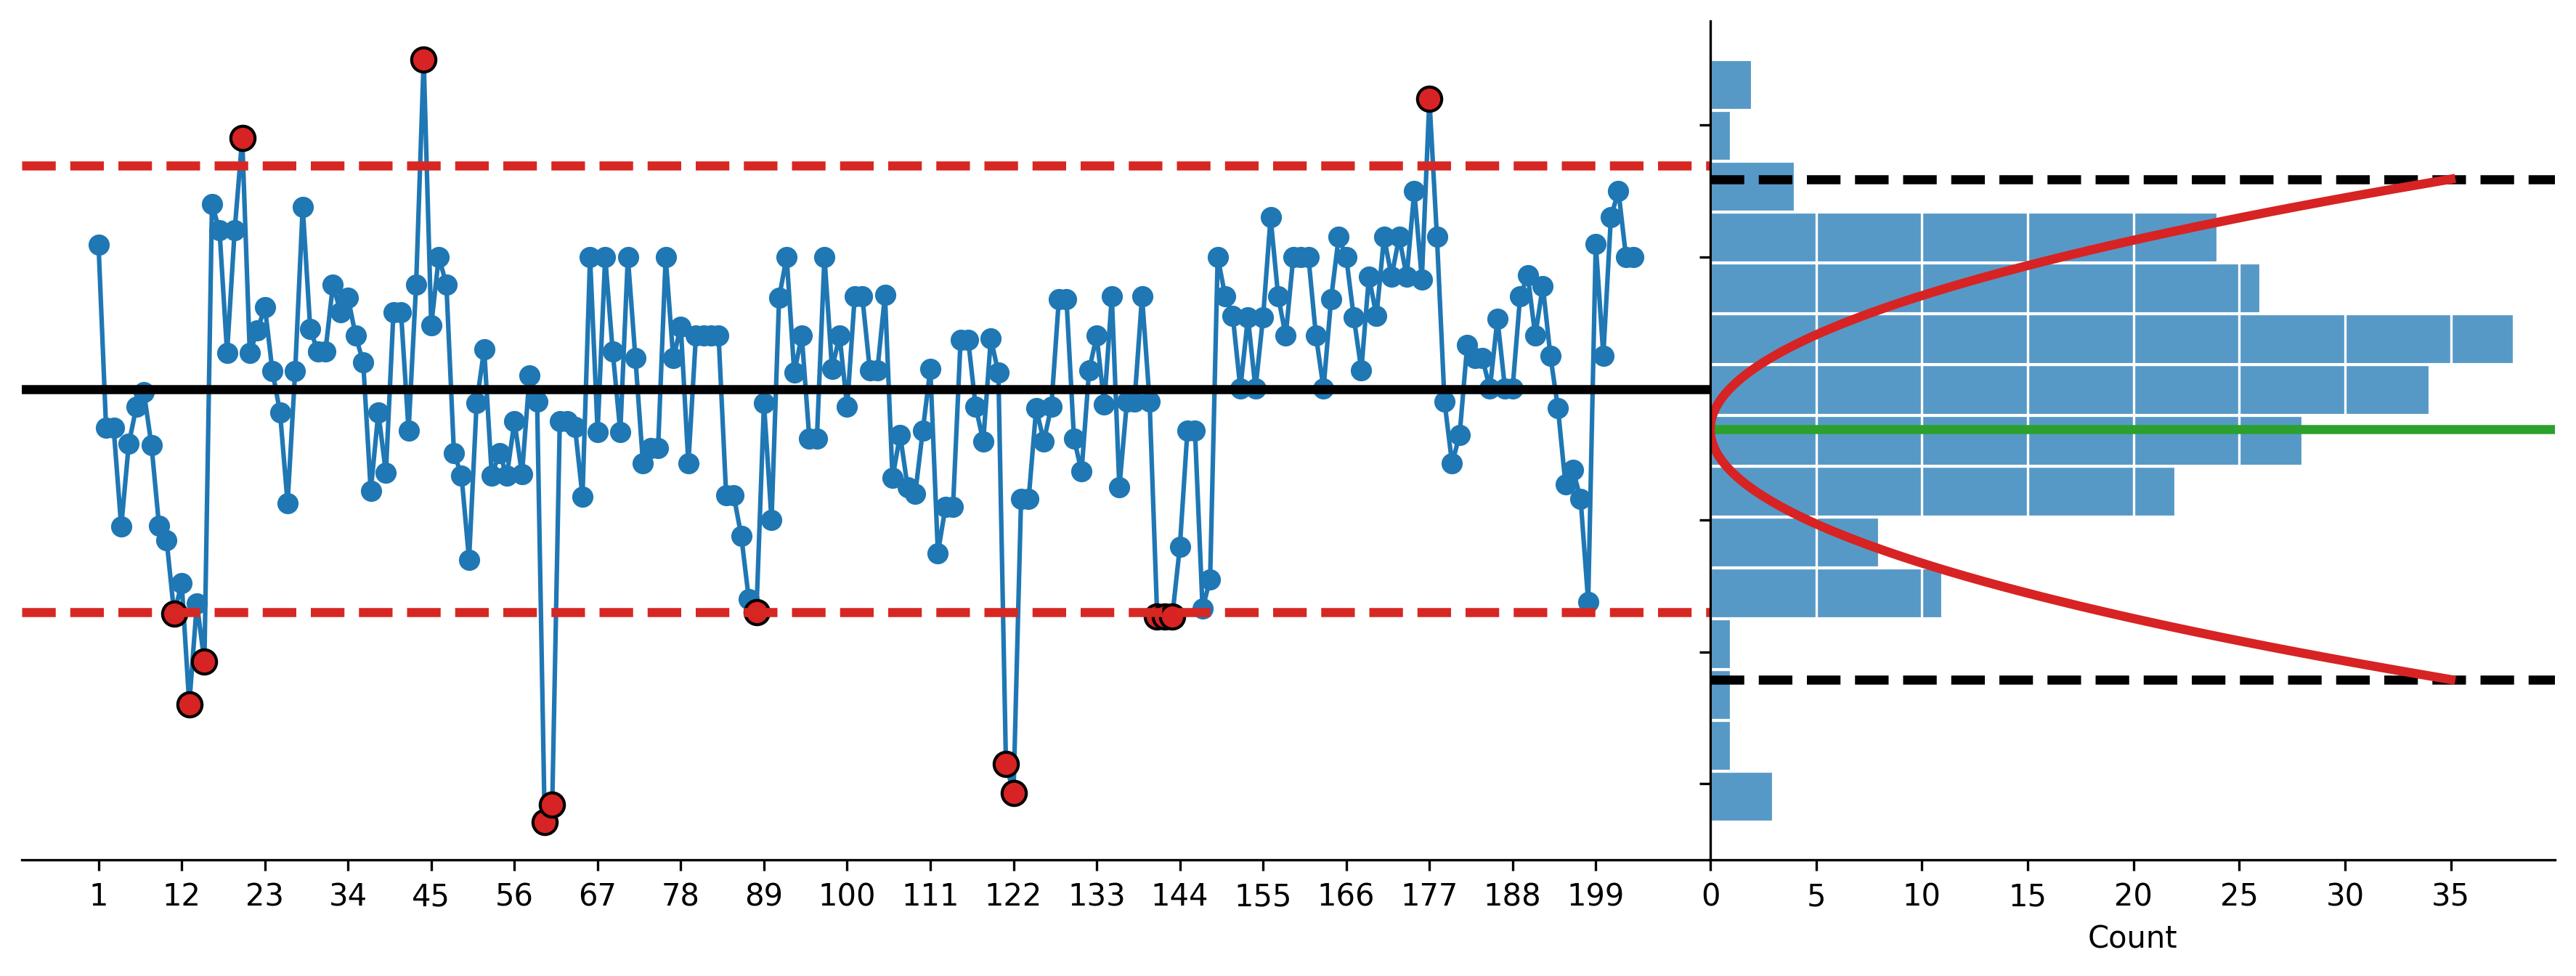

In [86]:
fig, ax = plt.subplots(figsize=(15,5), nrows=1, ncols=2, dpi=300, sharey=True, gridspec_kw={"width_ratios":[2,1]})

plt.subplots_adjust(wspace=0)

ax[0].plot(initial_df['Value'],
           data,
           marker='o')

ax[0].set_xticks(initial_df['Value'].iloc[::11])

# Red markers for values > 7.6
data_above = data.where(data > UPL)
data_below = data.where(data < LPL)

ax[0].plot(data_above, 
           marker='o', 
           linestyle='none',
           markersize=8,
           markeredgecolor='black',
           color='#d72323')

ax[0].plot(data_below, 
           marker='o', 
           linestyle='none',
           markersize=8,
           markeredgecolor='black',
           color='#d72323')


ax[0].axhline(5346.2, ls='--', lw=3, c='#d72723')
ax[0].axhline(3650.2, ls='--', lw=3, c='#d72723')
ax[0].axhline(4498.2, ls='-', lw=3, c='black')

sns.histplot(y=data,
             edgecolor='white',
             ax=ax[1])

ax[1].axhline(USL, ls='--', lw=3, c='black')
ax[1].axhline(LSL, ls='--', lw=3, c='black')
ax[1].axhline(target, ls='-', lw=3, c='tab:green')

ax[1].grid(axis='x', color='white')

# Get the maximum histogram count
counts, bins = np.histogram(data)
max_count = counts.max()

# y values from LSL to USL
y = np.linspace(LSL, USL, 200)

# Parabola with vertex at x = 0, y = target
a = 35 / max((LSL - target)**2, (USL - target)**2)

x = a * (y - target)**2

ax[1].plot(x, y, color='#d72323', lw=3)

sns.despine()

ax[0].spines['left'].set_visible(False)
ax[0].tick_params(axis='y', left=False, labelleft=False)

plt.show()

In [87]:
data2 = additional_df['Resistance']

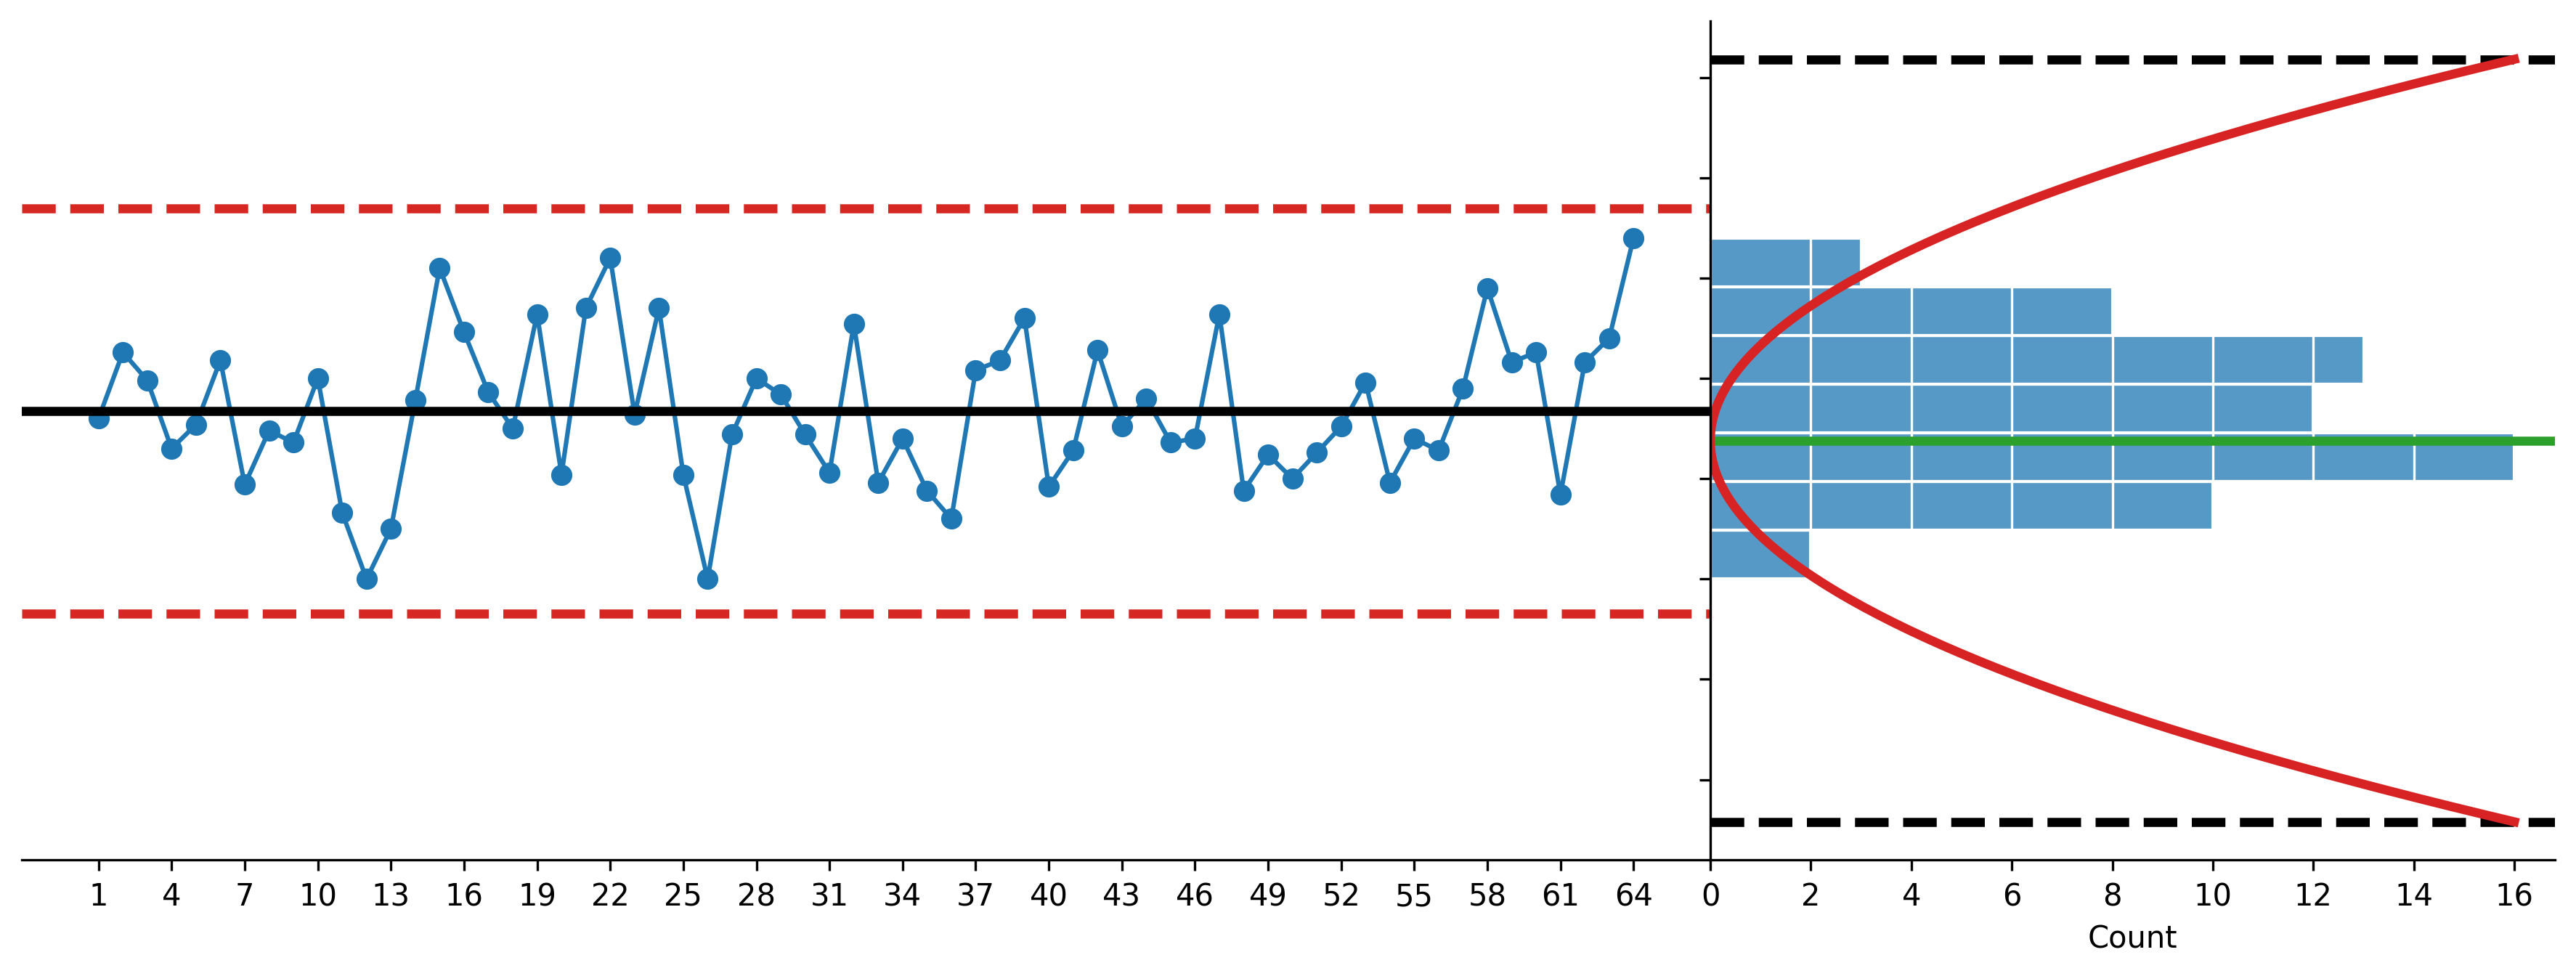

In [88]:
fig, ax = plt.subplots(figsize=(15,5), nrows=1, ncols=2, dpi=300, sharey=True, gridspec_kw={"width_ratios":[2,1]})

plt.subplots_adjust(wspace=0)

ax[0].plot(additional_df['Value'],
           data2,
           marker='o')

ax[0].set_xticks(additional_df['Value'].iloc[::3])

# Red markers for values > 7.6
data_above = data2.where(data2 > UPL)
data_below = data2.where(data2 < LPL)

ax[0].plot(data_above, 
           marker='o', 
           linestyle='none',
           markersize=8,
           markeredgecolor='black',
           color='#d72323')

ax[0].plot(data_below, 
           marker='o', 
           linestyle='none',
           markersize=8,
           markeredgecolor='black',
           color='#d72323')


ax[0].axhline(4922.7, ls='--', lw=3, c='#d72723')
ax[0].axhline(3912.9, ls='--', lw=3, c='#d72723')
ax[0].axhline(4417.8, ls='-', lw=3, c='black')

sns.histplot(y=data2,
             edgecolor='white',
             ax=ax[1])

ax[1].axhline(USL, ls='--', lw=3, c='black')
ax[1].axhline(LSL, ls='--', lw=3, c='black')
ax[1].axhline(target, ls='-', lw=3, c='tab:green')

ax[1].grid(axis='x', color='white')

# Get the maximum histogram count
counts, bins = np.histogram(data)
max_count = counts.max()

# y values from LSL to USL
y = np.linspace(LSL, USL, 200)

# Parabola with vertex at x = 0, y = target
a = 16 / max((LSL - target)**2, (USL - target)**2)

x = a * (y - target)**2

ax[1].plot(x, y, color='#d72323', lw=3)

sns.despine()

ax[0].spines['left'].set_visible(False)
ax[0].tick_params(axis='y', left=False, labelleft=False)

plt.show()